# Demanda de prepagas en Argentina: prepaga vía obra social frente a prepaga voluntaria

Este cuaderno desarrolla, de punta a punta, el análisis de la demanda de prepagas con la ENGHo 2017-2018: carga de las bases, definición del universo (**adultos de 18 años o más**), construcción de variables, estadística descriptiva ponderada, estimaciones econométricas y un catálogo de cuadros y gráficos. El foco está en dos panoramas (la **prepaga total** y las **cuatro formas de cobertura**) y en las **diferencias entre la prepaga vía obra social y la prepaga voluntaria**.

**Estructura**

| Módulo | Contenido |
|---|---|
| 0 | Configuración, librerías y estilo gráfico |
| 1 | Carga de las bases y de las réplicas bootstrap de INDEC |
| 2 | Universo de análisis y variable dependiente (cobertura de salud) |
| 3 | Construcción y limpieza de variables explicativas |
| 4 | Validaciones de la base final |
| 5 | Cuadros descriptivos: Tabla 1 (completa y compacta) y Tabla V (vía OS frente a voluntaria) |
| 6 | Catálogo de gráficos descriptivos: M1 a M9 (mercado) y V1 a V8 (vía OS frente a voluntaria) |
| 7 | Estimaciones: logit de prepaga total (A1 y A3), logit multinomial de las cuatro coberturas (B) y logit de voluntaria frente a vía OS (C), con errores por réplicas |
| 8 | Catálogo de resultados: E1 a E14 (tablas y gráficos de las estimaciones) |
| 9 | Pruebas de robustez |
| 10 | Exportación de tablas a Excel |

**Convenciones.** Las cifras descriptivas y las estimaciones usan el factor de expansión `pondera` **tal como viene en la base**, sin normalizar. Los modelos son de máxima verosimilitud ponderada (pseudoverosimilitud). **Todos los errores estándar, intervalos y p-valores se calculan con las 200 réplicas bootstrap de INDEC** (archivo `engho2018_replicas.txt`), siguiendo la Nota técnica n.º 4 de la ENGHo: cada estadística se calcula con `pondera` y con cada réplica, y el error estándar es la raíz del promedio de los cuadrados de las diferencias entre cada réplica y la estimación completa. Una única función (`error_replicas`) produce el error de cualquier cifra. Los intervalos son `estimación ± 1,96 × EE`. Los títulos de los gráficos son descriptivos y no afirman resultados: el mensaje de cada gráfico se redacta en el texto del trabajo.

## Módulo 0. Configuración, librerías y estilo

Se importan las librerías, se define la ruta de datos en Google Drive (`/content/drive/MyDrive/TP/Datos/`) y la carpeta donde se guardarán los resultados (gráficos en PNG de 300 dpi y tablas en Excel). Las estimaciones usan solo `numpy`, `pandas`, `scipy` y `scikit-learn`. Si el cuaderno se ejecuta fuera de Colab, las rutas pueden sobrescribirse con las variables de entorno `TP_DATOS` y `TP_SALIDA`.

`N_REP` es la cantidad de réplicas bootstrap que se usan (200, las que entrega INDEC). Puede reducirse con la variable de entorno `TP_NREP` solo para probar que el código corre.

El interruptor `TITULO_EN_IMAGEN` decide si los gráficos llevan título y subtítulo dentro de la imagen. Por defecto es `False`: el título va en el epígrafe del documento y la imagen conserva solo la fuente.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

try:
    display
except NameError:  # ejecución fuera de Jupyter
    def display(x):
        print(x.to_string() if hasattr(x, "to_string") else x)

# ---------- Rutas ----------
RUTA_DATOS  = "/content/drive/MyDrive/TP/Datos/"
RUTA_SALIDA = "/content/drive/MyDrive/TP/Resultados/"

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:  # ejecución fuera de Colab
    RUTA_DATOS  = os.environ.get("TP_DATOS", RUTA_DATOS)
    RUTA_SALIDA = os.environ.get("TP_SALIDA", "./Resultados/")

N_REP = int(os.environ.get("TP_NREP", "200"))      # réplicas bootstrap de INDEC (máximo 200)

RUTA_GRAFICOS = os.path.join(RUTA_SALIDA, "graficos")
os.makedirs(RUTA_GRAFICOS, exist_ok=True)

# ---------- Estilo gráfico ----------
TITULO_EN_IMAGEN = False

ETQ_COB = ["Sin cobertura / pública", "Obra social", "Prepaga vía OS", "Prepaga voluntaria"]
COL = {
    ETQ_COB[0]: "#B9C0CA",   # gris
    ETQ_COB[1]: "#1F3A5F",   # azul marino
    ETQ_COB[2]: "#2A9D8F",   # verde azulado
    ETQ_COB[3]: "#E9A23B",   # ámbar
}
TINTA = "#222B36"
GRILLA = "#E4E8EE"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 10.5, "text.color": TINTA,
    "axes.edgecolor": "#9AA3AF", "axes.labelcolor": TINTA, "axes.titlesize": 11.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})

FUENTE = "Fuente: elaboración propia con microdatos de la ENGHo 2017-2018 (INDEC). Cifras ponderadas con pondera."

def miles(n):
    return f"{int(round(n)):,}".replace(",", ".")

def fmt_num(x, d=0):
    if pd.isna(x):
        return ""
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def fmt_pct(x, d=1):
    return "" if pd.isna(x) else fmt_num(x, d) + "%"

def fmt_p(p):
    return "<0,001" if p < 0.001 else fmt_num(p, 3)

def pct_pond(x, w):
    # Porcentaje ponderado de una variable binaria (o booleana)
    return np.average(x, weights=w) * 100 if len(x) else np.nan

print("Datos:", RUTA_DATOS)
print("Salida:", RUTA_SALIDA)

Mounted at /content/drive
Datos: /content/drive/MyDrive/TP/Datos/
Salida: /content/drive/MyDrive/TP/Resultados/


## Módulo 1. Carga de las bases

Se leen las dos tablas necesarias de la ENGHo 2017-2018 (separador `|`, decimal `.`):

- **Personas**: una fila por miembro del hogar. De aquí salen la cobertura de salud, las características individuales, el factor de expansión y el ingreso individual.
- **Hogares**: una fila por hogar. De aquí se extraen únicamente variables auxiliares (ingreso per cápita del hogar y marca de imputación del ingreso del hogar).
- **Réplicas**: una fila por hogar con 200 factores de expansión replicados (bootstrap). INDEC no publica los estratos ni las unidades de muestreo del diseño; en su lugar entrega estas réplicas, que reproducen el diseño y los ajustes por no respuesta y calibración. Se aplican también a las personas del hogar.

El archivo de réplicas (`engho2018_replicas.txt`) debe estar en la misma carpeta de datos. La búsqueda del archivo recorre las subcarpetas y no distingue mayúsculas, de modo que funciona con nombres como `ENGHo2018_personas.txt` o `engho2018_personas.txt`, estén o no dentro de una carpeta propia.

**Cómo se calcula el error de una cifra.** Para cualquier estadística θ, se calcula θ̂ con `pondera` y θ̂(b) con cada réplica b = 1, …, B. La varianza bootstrap es `v(θ̂) = (1/B) Σ_b (θ̂(b) − θ̂)²` y el error estándar es su raíz cuadrada (Nota técnica n.º 4 de INDEC, sección 5.2). La función `error_replicas` aplica esa fórmula a cualquier estadística, incluidos los modelos. Una réplica donde la estimación no converge se descarta y se informa.

In [2]:
def buscar_archivo(clave):
    for raiz, _, archivos in os.walk(RUTA_DATOS):
        for f in sorted(archivos):
            if clave in f.lower() and f.lower().endswith(".txt"):
                return os.path.join(raiz, f)
    raise FileNotFoundError(f"No se encontró un .txt con '{clave}' en {RUTA_DATOS}")

personas = pd.read_csv(buscar_archivo("personas"), sep="|", low_memory=False)
hogares  = pd.read_csv(buscar_archivo("hogares"),  sep="|", low_memory=False)

print(f"Personas: {personas.shape[0]:,} filas x {personas.shape[1]} columnas")
print(f"Hogares : {hogares.shape[0]:,} filas x {hogares.shape[1]} columnas")
assert hogares["id"].is_unique, "id duplicado en hogares"
assert not personas.duplicated(["id", "miembro"]).any(), "clave id-miembro duplicada en personas"
assert (personas["pondera"] > 0).all(), "factor de expansión no positivo"
print(f"Población expandida (personas): {miles(personas['pondera'].sum())}")

replicas = pd.read_csv(buscar_archivo("replicas"), sep="|", low_memory=False)
COLS_REP = sorted([c for c in replicas.columns if c.lower() != "id"], key=lambda c: int(''.join(ch for ch in c if ch.isdigit())))
assert set(replicas["id"]) == set(hogares["id"]), "las réplicas no coinciden con los hogares"
assert replicas[COLS_REP].notna().all().all(), "hay réplicas con valores faltantes"
assert 1 <= N_REP <= len(COLS_REP), f"N_REP debe estar entre 1 y {len(COLS_REP)}"
print(f"Réplicas: {len(replicas):,} hogares x {len(COLS_REP)} réplicas (se usan {N_REP})")

# ---------- Funciones de error por réplicas ----------
def error_replicas(est_fn, w0, Rw):
    # est_fn(w) -> vector de estimaciones con los pesos w. Devuelve (estimación completa, EE bootstrap, réplicas válidas).
    th0 = np.atleast_1d(np.asarray(est_fn(w0), float))
    vals = []
    for b in range(Rw.shape[1]):
        try:
            vb = np.atleast_1d(np.asarray(est_fn(Rw[:, b]), float))
            if np.all(np.isfinite(vb)):
                vals.append(vb)
        except Exception:
            continue
    if not vals:
        return th0, np.full_like(th0, np.nan), 0, np.empty((0, len(th0)))
    V = np.array(vals)
    return th0, np.sqrt(np.mean((V - th0[None, :]) ** 2, axis=0)), len(vals), V

def cuantil_np(x, w, q):
    # Cuantil ponderado: primer valor cuya frecuencia acumulada ponderada alcanza q
    o = np.argsort(x)
    xs, cw = x[o], np.cumsum(w[o]) / w.sum()
    return xs[min(np.searchsorted(cw, q), len(xs) - 1)]

def tasa_grupos(codigos, ind, w0, Rw):
    # Tasa ponderada (%) de un indicador 0/1 dentro de cada grupo (códigos enteros 0..G-1) y su EE por réplicas
    G = int(codigos.max()) + 1
    f = lambda w: np.bincount(codigos, w * ind, G) / np.bincount(codigos, w, G) * 100
    th, se, nv, _ = error_replicas(f, w0, Rw)
    return th, se

Personas: 68,725 filas x 158 columnas
Hogares : 21,547 filas x 134 columnas
Población expandida (personas): 40.370.737
Réplicas: 21,547 hogares x 200 réplicas (se usan 200)


## Módulo 2. Universo de análisis y variable dependiente

**Universo:** todas las personas de **18 años o más** (`cp03 >= 18`). La unidad de observación es la persona y los errores estándar se agrupan por hogar. La cobertura de salud se declara por persona, de modo que la unidad natural del análisis es el adulto. Se excluye a los menores de 18 años porque su cobertura depende de la de sus adultos.

**Variable dependiente `cobertura`** (cuatro categorías mutuamente excluyentes). Las variables `cp23_02`, `cp23_03` y `cp23_04` se solapan entre sí, por lo que se aplica una jerarquía que sigue la lógica de la variable `comed_pub` de INDEC (plan estatal < obra social < prepaga):

| Prioridad | Categoría | Regla |
|---|---|---|
| 1 | Prepaga voluntaria | `cp23_04 == 1` |
| 2 | Prepaga vía OS | `cp23_03 == 1` |
| 3 | Obra social | `cp23_02 == 1` o PAMI (`cp23_01 == 1`) |
| 4 | Sin cobertura / pública | resto |

PAMI queda **dentro de la categoría obra social**: no se trata como una categoría aparte. Se lo tiene en cuenta de tres maneras: se informa su peso dentro de la obra social (Tabla 1), se controla por la edad y por percibir jubilación o pensión en los modelos, y se repiten las estimaciones principales sin los adultos que declaran PAMI (Módulo 9). No puede entrar como regresor del multinomial: nadie en "sin cobertura" declara PAMI, de modo que su coeficiente no se identifica (predicción perfecta).

Quien declara a la vez prepaga vía OS y voluntaria se descarta. Se construye además `prepaga_total` (1 = prepaga vía OS o voluntaria), que mide la demanda total de prepagas, y `complemento` (1 = declara además obra social o PAMI), que sirve para identificar la parte de la prepaga que complementa a otra cobertura y no la sustituye. Al final se muestra el embudo de observaciones.

In [3]:
# ---------- Variables auxiliares construidas desde la base de personas ----------
VARS_HOGAR = ["id", "ingpch", "m_ingtoth"]

adultos = (personas[personas["cp03"] >= 18]
           .merge(hogares[VARS_HOGAR], on="id", how="left", validate="m:1"))

# ---------- Embudo de filtros ----------
def fila_embudo(paso, d):
    return (paso, len(d), d["pondera"].sum())

embudo = [fila_embudo("Adultos de 18 años o más (cp03 >= 18)", adultos)]

df = adultos[adultos["ingpch"] > 0].copy()
embudo.append(fila_embudo("Con ingreso per cápita del hogar positivo (ingpch > 0)", df))

ns_cobertura = df[["cp23_01", "cp23_02", "cp23_03", "cp23_04"]].eq(99).any(axis=1)
df = df[~ns_cobertura].copy()
embudo.append(fila_embudo("Sin Ns/nr en cobertura de salud (cp23_01 a cp23_04)", df))

df = df[df["niveled"] != 99].copy()
embudo.append(fila_embudo("Sin Ns/nr en nivel educativo (niveled)", df))

# ---------- Variable dependiente ----------
vol = df["cp23_04"] == 1
via = df["cp23_03"] == 1
df["cobertura"] = np.select(
    [vol & via, vol, via, (df["cp23_02"] == 1) | (df["cp23_01"] == 1)],
    ["ambas", ETQ_COB[3], ETQ_COB[2], ETQ_COB[1]],
    default=ETQ_COB[0],
)
df = df[df["cobertura"] != "ambas"].copy()
embudo.append(fila_embudo("Sin cobertura 'ambas prepagas'", df))

df["cobertura"] = pd.Categorical(df["cobertura"], categories=ETQ_COB, ordered=True)
df["cob_cod"] = df["cobertura"].cat.codes                     # 0 = sin cobertura, 1 = OS, 2 = vía OS, 3 = voluntaria
df["prepaga_total"] = np.where(df["cobertura"].isin(ETQ_COB[2:]), 1, 0)
df["pami"] = (df["cp23_01"] == 1).astype(int)
df["complemento"] = ((df["cp23_02"] == 1) | (df["cp23_01"] == 1)).astype(int)

tabla_embudo = pd.DataFrame(embudo, columns=["Paso", "N restante", "Población expandida"])
tabla_embudo["Excluidos"] = tabla_embudo["N restante"].diff().fillna(0).abs().astype(int)
tabla_embudo["Población expandida"] = tabla_embudo["Población expandida"].round(0).astype(int)
display(tabla_embudo)

dist = (df.groupby("cobertura", observed=True)
          .agg(N=("pondera", "size"), Poblacion=("pondera", "sum")))
dist["Porcentaje ponderado"] = (dist["Poblacion"] / dist["Poblacion"].sum() * 100).round(1)
dist["Porcentaje sin ponderar"] = (dist["N"] / dist["N"].sum() * 100).round(1)
dist["Poblacion"] = dist["Poblacion"].round(0).astype(int)
display(dist)

,Paso,N restante,Población expandida,Excluidos
0,Adultos de 18 años o más (cp03 >= 18),48574,28638099,0
1,Con ingreso per cápita del hogar positivo (ing...,48549,28624106,25
2,Sin Ns/nr en cobertura de salud (cp23_01 a cp2...,48467,28576569,82
3,Sin Ns/nr en nivel educativo (niveled),48370,28498354,97
4,Sin cobertura 'ambas prepagas',48363,28494280,7


,N,Poblacion,Porcentaje ponderado,Porcentaje sin ponderar
cobertura,,,,
Sin cobertura / pública,17266,9470873,33.2,35.7
Obra social,27142,15907976,55.8,56.1
Prepaga vía OS,1843,1538688,5.4,3.8
Prepaga voluntaria,2112,1576743,5.5,4.4


## Módulo 3. Construcción y limpieza de variables explicativas

Todas las variables se construyen sobre el universo ya filtrado. La especificación es deliberadamente corta: cada variable responde a una hipótesis sobre la demanda.

| Dimensión | Variable | Construcción |
|---|---|---|
| Económica | `log_ingpch` | logaritmo natural de `ingpch` (ingreso per cápita del hogar). Es la medida de recursos de todos los adultos, perciban o no ingresos propios |
| | `quintil` | quintil **ponderado** de `ingpch`, calculado sobre la población adulta (solo para la descriptiva) |
| | `log_ingtotp` | logaritmo de `ingtotp` (ingreso individual, solo perceptores), solo para robustez |
| Demográfica | `edad`, `edad2` | `cp03` y `cp03² / 100` |
| | `mujer` | `cp13 == 2` |
| Capital humano | `educ` | `niveled`, con "sin instrucción" fusionado a "primario incompleto" (referencia) |
| Riesgo | `dificultad` | `dif_lp == 1` (dificultad de largo plazo) |
| Laboral | `cond_lab` | asalariado registrado (referencia), asalariado no registrado, independiente/patrón, desocupado, inactivo |
| | `jubilado` | `ijubilacion > 0` |
| Geográfica | `region` | seis regiones estadísticas (referencia: Metropolitana) |
| Calidad del dato | `hogar_imputado` | ingreso del hogar con imputación (`m_ingtoth == 1`) |

Se omite el gasto en salud: incluye la cuota de la propia prepaga y no puede entrar en los modelos.

In [4]:
def cuantil_pond(x, w, q):
    # Cuantil ponderado: primer valor cuya frecuencia acumulada ponderada alcanza q
    o = np.argsort(x.values)
    xs, cw = x.values[o], np.cumsum(w.values[o]) / w.sum()
    return xs[np.searchsorted(cw, q)]

# ---------- Económicas ----------
df["log_ingpch"] = np.log(df["ingpch"])
cortes_q = [cuantil_pond(df["ingpch"], df["pondera"], q) for q in (0.2, 0.4, 0.6, 0.8)]
df["quintil"] = np.searchsorted(cortes_q, df["ingpch"].values, side="left") + 1
df["perceptor"] = (df["ingtotp"] > 0).astype(int)
df["log_ingtotp"] = np.where(df["ingtotp"] > 0, np.log(df["ingtotp"].where(df["ingtotp"] > 0)), np.nan)

# ---------- Demográficas ----------
df["edad"] = df["cp03"].astype(float)
df["edad2"] = df["edad"] ** 2 / 100
df["mujer"] = (df["cp13"] == 2).astype(int)

# ---------- Capital humano ----------
df["educ"] = df["niveled"].replace({7: 1}).astype(int)
NIV_EDUC = {1: "Hasta primario incompleto", 2: "Primario completo", 3: "Secundario incompleto",
            4: "Secundario completo", 5: "Universitario incompleto", 6: "Universitario completo"}

# ---------- Riesgo ----------
df["dificultad"] = (df["dif_lp"] == 1).astype(int)

# ---------- Laboral ----------
df["cond_lab"] = np.select(
    [(df["estado"] == 1) & (df["cp44"] == 1) & (df["cp39"] == 1),
     (df["estado"] == 1) & (df["cp44"] == 1),
     (df["estado"] == 1),
     (df["estado"] == 2),
     (df["estado"] == 3)],
    ["asal_reg", "asal_noreg", "indep", "desocupado", "inactivo"],
    default="sin_dato",
)
COND_LAB = {"asal_reg": "Asalariado/a registrado/a", "asal_noreg": "Asalariado/a no registrado/a",
            "indep": "Independiente / patrón", "desocupado": "Desocupado/a", "inactivo": "Inactivo/a"}
df["jubilado"] = (df["ijubilacion"].fillna(0) > 0).astype(int)

# ---------- Geográfica ----------
REGIONES = {1: "Metropolitana", 2: "Pampeana", 3: "Noroeste", 4: "Noreste", 5: "Cuyo", 6: "Patagonia"}
PROVINCIAS = {2: "CABA", 6: "Buenos Aires", 10: "Catamarca", 14: "Córdoba", 18: "Corrientes", 22: "Chaco",
              26: "Chubut", 30: "Entre Ríos", 34: "Formosa", 38: "Jujuy", 42: "La Pampa", 46: "La Rioja",
              50: "Mendoza", 54: "Misiones", 58: "Neuquén", 62: "Río Negro", 66: "Salta", 70: "San Juan",
              74: "San Luis", 78: "Santa Cruz", 82: "Santa Fe", 86: "Santiago del Estero", 90: "Tucumán",
              94: "Tierra del Fuego"}
df["region"] = df["region"].map(REGIONES)
df["provincia_nombre"] = df["provincia"].map(PROVINCIAS)

# ---------- Calidad del dato ----------
df["hogar_imputado"] = (df["m_ingtoth"] == 1).astype(int)

df = df.reset_index(drop=True)
print(f"Base de análisis: {len(df):,} adultos ({miles(df['pondera'].sum())} personas expandidas)")
print("Cortes de los quintiles de ingreso per cápita del hogar ($):", [miles(c) for c in cortes_q])

# ---------- Réplicas alineadas con las filas de df ----------
Rall = df[["id"]].merge(replicas[["id"] + COLS_REP], on="id", how="left")[COLS_REP].values
assert Rall.shape == (len(df), len(COLS_REP)) and np.isfinite(Rall).all()

def RW(d):
    # Réplicas de las filas de d (d conserva el índice de df)
    return Rall[d.index.values][:, :N_REP]

Base de análisis: 48,363 adultos (28.494.280 personas expandidas)
Cortes de los quintiles de ingreso per cápita del hogar ($): ['4.300', '6.917', '9.862', '15.667']


## Módulo 4. Validaciones de la base final

Se verifica que la base no tenga valores faltantes en las variables que entran a los modelos, que las categorías estén bien codificadas, que los quintiles ponderados reproduzcan el 20% de la población y que el tamaño de las categorías de cobertura alcance para estimar.

In [5]:
VARS_MODELO = ["log_ingpch", "edad", "edad2", "mujer", "educ", "dificultad",
               "cond_lab", "jubilado", "region", "cobertura", "prepaga_total"]

faltantes = df[VARS_MODELO].isna().sum()
assert faltantes.sum() == 0, faltantes[faltantes > 0]
assert (df["cond_lab"] != "sin_dato").all(), "hay adultos sin condición laboral"
assert df["educ"].between(1, 6).all()
assert set(df["region"].unique()) == set(REGIONES.values())
assert df["provincia_nombre"].notna().all()
assert df["edad"].min() >= 18
assert df["ingpch"].gt(0).all()
assert df.index.equals(pd.RangeIndex(len(df)))
cuota_q = df.groupby("quintil")["pondera"].sum() / df["pondera"].sum()
assert np.allclose(cuota_q, 0.2, atol=0.01), cuota_q
assert (df["cobertura"].value_counts() > 500).all(), "categoría de cobertura con muy pocos casos"
assert (df.loc[df["cobertura"] == ETQ_COB[0], "pami"] == 0).all(), "hay PAMI entre los sin cobertura"

print("Validaciones superadas.")
print(f"N final: {len(df):,}")
print(f"Prepaga total: {pct_pond(df['prepaga_total'], df['pondera']):.1f}% de la población adulta (sin ponderar: {df['prepaga_total'].mean()*100:.1f}%)")
obra = df[df["cobertura"] == ETQ_COB[1]]
print(f"PAMI dentro de Obra social: {pct_pond(obra['pami'], obra['pondera']):.1f}% ({int(obra['pami'].sum()):,} adultos)")
volu = df[df["cobertura"] == ETQ_COB[3]]
print(f"Prepaga voluntaria con obra social o PAMI declarados: {pct_pond(volu['complemento'], volu['pondera']):.1f}%")
print(f"Hogares con ingreso imputado: {pct_pond(df['hogar_imputado'], df['pondera']):.1f}%")

df.to_csv(os.path.join(RUTA_SALIDA, "base_analisis_adultos.csv"), index=False)

Validaciones superadas.
N final: 48,363
Prepaga total: 10.9% de la población adulta (sin ponderar: 8.2%)
PAMI dentro de Obra social: 25.1% (6,508 adultos)
Prepaga voluntaria con obra social o PAMI declarados: 27.9%
Hogares con ingreso imputado: 30.7%


## Módulo 5. Cuadros descriptivos

Tres cuadros, todos **ponderados** con `pondera` (medias, proporciones y medianas), con el error de cada cifra calculado con las réplicas de INDEC:

- **Tabla 1 (completa)**: la población adulta y cada una de las cuatro coberturas, con muchas filas. Es el insumo para elegir.
- **Tabla 1c (compacta, exhibit M10)**: las filas que mejor caracterizan al mercado.
- **Tabla V (exhibit V7)**: prepaga vía OS frente a prepaga voluntaria, con la diferencia entre ambas y su p-valor (prueba z con el error por réplicas).

**Calidad de las cifras.** Cada cifra lleva una marca según el estándar de INDEC (Nota técnica n.º 4, Cuadro 4). `‡` indica estimación **no confiable**: menos de 100 casos, proporción menor al 3% o coeficiente de variación (CV) mayor al 33,3%. `†` indica estimación **poco confiable**: CV entre 16,6% y 33,3%. Las celdas que valen cero por definición (por ejemplo, PAMI entre quienes no tienen cobertura) no se marcan. El CV de cada celda está en las tablas con sufijo `_cv`, que se exportan al Excel.

Los valores monetarios están en pesos corrientes de 2017-2018. El manual de INDEC recomienda comparar niveles relativos entre grupos y no interpretar los valores absolutos.

In [6]:
# Variables auxiliares solo para los cuadros
df["univ"] = (df["educ"] >= 5).astype(int)
df["asal_reg"] = (df["cond_lab"] == "asal_reg").astype(int)
df["indep"] = (df["cond_lab"] == "indep").astype(int)
df["inactivo"] = (df["cond_lab"] == "inactivo").astype(int)
df["metro"] = (df["region"] == "Metropolitana").astype(int)

def estadistico(y, w, estad):
    return np.average(y, weights=w) if estad == "mean" else cuantil_np(y, w, 0.5)

def celda(s, y, estad, es_prop, dec):
    # Cifra, CV y marca de calidad de INDEC para el subconjunto s (y: valores de s)
    th, se, nv, _ = error_replicas(lambda w: estadistico(y, w, estad), s["pondera"].values, RW(s))
    est, ee = float(th[0]), float(se[0])
    cv = ee / abs(est) * 100 if est != 0 else np.nan
    marca = ""
    if not (est == 0 and ee == 0):
        if len(s) < 100 or (es_prop and est * 100 < 3) or (pd.notna(cv) and cv > 33.3):
            marca = " ‡"
        elif pd.notna(cv) and cv > 16.6:
            marca = " †"
    texto = (fmt_pct(est * 100, dec) if es_prop else fmt_num(est, dec)) + marca
    return texto, ("" if pd.isna(cv) else fmt_num(cv, 1) + "%")

def diferencia(sa, ya, sb, yb, estad, es_prop, dec):
    # Diferencia (b - a) con su error por réplicas y p-valor de la prueba z
    Ra, Rb = RW(sa), RW(sb)
    wa, wb = sa["pondera"].values, sb["pondera"].values
    d0 = estadistico(yb, wb, estad) - estadistico(ya, wa, estad)
    reps = []
    for b in range(Ra.shape[1]):
        try:
            reps.append(estadistico(yb, Rb[:, b], estad) - estadistico(ya, Ra[:, b], estad))
        except Exception:
            continue
    reps = np.array(reps)
    se = float(np.sqrt(np.mean((reps - d0) ** 2))) if len(reps) else np.nan
    esc = 100 if es_prop else 1
    p = 2 * stats.norm.sf(abs(d0 / se)) if (pd.notna(se) and se > 0) else np.nan
    return f"{d0 * esc:+.{dec}f}".replace(".", ","), (fmt_p(p) if pd.notna(p) else "")

def construir_tabla(subs, specs, base, diff=None):
    # subs: columnas (nombre -> subconjunto de df); diff: (nombre_a, nombre_b) agrega la diferencia b - a
    filas, filas_cv = [], []

    def fila(label, celdas=None, extra=("", "")):
        f1, f2 = {"Variable": label}, {"Variable": label}
        for k, c in zip(subs.keys(), celdas if celdas else [("", "")] * len(subs)):
            f1[k], f2[k] = c
        if diff:
            f1["Diferencia"], f1["p-valor"] = extra
            f2["Diferencia"], f2["p-valor"] = "", ""
        filas.append(f1)
        filas_cv.append(f2)

    def una_fila(label, col, estad, es_prop, dec, nivel=None, solo_perc=False):
        def datos(s):
            s = s[s["perceptor"] == 1] if solo_perc else s
            y = (s[col] == nivel).astype(float).values if nivel is not None else s[col].values.astype(float)
            return s, y
        celdas = []
        for s in subs.values():
            s2, y2 = datos(s)
            celdas.append(celda(s2, y2, estad, es_prop, dec))
        extra = ("", "")
        if diff:
            (sa, ya), (sb, yb) = datos(subs[diff[0]]), datos(subs[diff[1]])
            extra = diferencia(sa, ya, sb, yb, estad, es_prop, 1 if es_prop else dec)
        fila(label, celdas, extra)

    for sp in specs:
        tipo = sp[0]
        if tipo == "sec":
            fila(sp[1].upper())
        elif tipo == "n":
            fila("N (adultos, muestra)", [(miles(len(s)), "") for s in subs.values()])
            fila("Población expandida (miles)", [(miles(s["pondera"].sum() / 1000), "") for s in subs.values()])
            fila("% de la población de referencia", [(fmt_pct(s["pondera"].sum() / base["pondera"].sum() * 100), "") for s in subs.values()])
        elif tipo == "cont":
            _, label, col, estad, dec, _test_log, solo_perc = sp
            una_fila(label, col, estad, False, dec, solo_perc=solo_perc)
        elif tipo == "bin":
            _, label, col = sp
            una_fila(label, col, "mean", True, 1)
        elif tipo == "cat":
            _, label, col, niveles, etiquetas = sp
            fila(label)
            for nv in niveles:
                una_fila("     " + etiquetas[nv], col, "mean", True, 1, nivel=nv)
    return pd.DataFrame(filas), pd.DataFrame(filas_cv)

SPECS_COMPLETA = [
    ("n",),
    ("sec", "Económicas"),
    ("cont", "Ingreso per cápita del hogar, mediana ($)", "ingpch", "median", 0, True, False),
    ("cont", "Ingreso per cápita del hogar, media ($)", "ingpch", "mean", 0, True, False),
    ("bin", "Percibe ingresos propios (%)", "perceptor"),
    ("cont", "Ingreso individual de perceptores, mediana ($)", "ingtotp", "median", 0, True, True),
    ("sec", "Demográficas"),
    ("cont", "Edad, media (años)", "edad", "mean", 1, False, False),
    ("bin", "Mujeres (%)", "mujer"),
    ("sec", "Capital humano"),
    ("cat", "Nivel educativo (%)", "educ", list(NIV_EDUC), NIV_EDUC),
    ("sec", "Inserción laboral"),
    ("cat", "Condición laboral (%)", "cond_lab", list(COND_LAB), COND_LAB),
    ("bin", "Percibe jubilación o pensión (%)", "jubilado"),
    ("bin", "Declara PAMI (%)", "pami"),
    ("sec", "Riesgo"),
    ("bin", "Con dificultad de largo plazo (%)", "dificultad"),
    ("sec", "Región"),
    ("cat", "Región (%)", "region", list(REGIONES.values()), {r: r for r in REGIONES.values()}),
]

SPECS_COMPACTA = [
    ("n",),
    ("cont", "Ingreso per cápita del hogar, mediana ($)", "ingpch", "median", 0, True, False),
    ("cont", "Edad, media (años)", "edad", "mean", 1, False, False),
    ("bin", "Mujeres (%)", "mujer"),
    ("bin", "Universitario, completo o incompleto (%)", "univ"),
    ("bin", "Asalariado/a registrado/a (%)", "asal_reg"),
    ("bin", "Independiente / patrón (%)", "indep"),
    ("bin", "Inactivo/a (%)", "inactivo"),
    ("bin", "Percibe jubilación o pensión (%)", "jubilado"),
    ("bin", "Declara PAMI (%)", "pami"),
    ("bin", "Con dificultad de largo plazo (%)", "dificultad"),
    ("bin", "Región Metropolitana (%)", "metro"),
]

subs4 = {"Total": df, **{g: df[df["cobertura"] == g] for g in ETQ_COB}}
tabla1, tabla1_cv = construir_tabla(subs4, SPECS_COMPLETA, df)
tabla1c, tabla1c_cv = construir_tabla(subs4, SPECS_COMPACTA, df)
display(tabla1)

,Variable,Total,Sin cobertura / pública,Obra social,Prepaga vía OS,Prepaga voluntaria
0,"N (adultos, muestra)",48.363,17.266,27.142,1.843,2.112
1,Población expandida (miles),28.494,9.471,15.908,1.539,1.577
2,% de la población de referencia,"100,0%","33,2%","55,8%","5,4%","5,5%"
3,ECONÓMICAS,,,,,
4,"Ingreso per cápita del hogar, mediana ($)",8.200,4.975,9.583,15.961,15.167
5,"Ingreso per cápita del hogar, media ($)",11.285,6.201,12.677,19.841,19.429
6,Percibe ingresos propios (%),"85,3%","78,9%","88,7%","87,1%","87,5%"
7,"Ingreso individual de perceptores, mediana ($)",12.000,7.000,14.817,24.403,18.980
8,DEMOGRÁFICAS,,,,,
9,"Edad, media (años)","43,9","35,8","48,5","41,8","48,0"


### Tabla 1c (M10) y Tabla V (V7)

La Tabla 1c es la versión corta de la Tabla 1. La Tabla V compara solo a quienes tienen prepaga: la columna "Prepaga (total)" reúne a ambos tipos y las dos últimas columnas dan la diferencia entre voluntaria y vía OS (en p.p. para proporciones, en las unidades de la variable para medias y medianas) y el p-valor de la prueba z. La fila "Declara además obra social o PAMI" identifica la parte de la prepaga que complementa a otra cobertura.

In [7]:
display(tabla1c)

dprep = df[df["cobertura"].isin(ETQ_COB[2:])].copy()
subsV = {"Prepaga (total)": dprep, ETQ_COB[2]: dprep[dprep["cobertura"] == ETQ_COB[2]],
         ETQ_COB[3]: dprep[dprep["cobertura"] == ETQ_COB[3]]}
SPECS_V = [
    ("n",),
    ("sec", "Económicas"),
    ("cont", "Ingreso per cápita del hogar, mediana ($)", "ingpch", "median", 0, True, False),
    ("cont", "Ingreso per cápita del hogar, media ($)", "ingpch", "mean", 0, True, False),
    ("sec", "Demográficas y riesgo"),
    ("cont", "Edad, media (años)", "edad", "mean", 1, False, False),
    ("bin", "Mujeres (%)", "mujer"),
    ("bin", "Con dificultad de largo plazo (%)", "dificultad"),
    ("sec", "Capital humano"),
    ("bin", "Universitario, completo o incompleto (%)", "univ"),
    ("sec", "Inserción laboral"),
    ("bin", "Asalariado/a registrado/a (%)", "asal_reg"),
    ("bin", "Independiente / patrón (%)", "indep"),
    ("bin", "Inactivo/a (%)", "inactivo"),
    ("bin", "Percibe jubilación o pensión (%)", "jubilado"),
    ("sec", "Otras coberturas declaradas"),
    ("bin", "Declara PAMI (%)", "pami"),
    ("bin", "Declara además obra social o PAMI (%)", "complemento"),
    ("sec", "Región"),
    ("bin", "Región Metropolitana (%)", "metro"),
]
tablaV, tablaV_cv = construir_tabla(subsV, SPECS_V, dprep, diff=(ETQ_COB[2], ETQ_COB[3]))
display(tablaV)

,Variable,Total,Sin cobertura / pública,Obra social,Prepaga vía OS,Prepaga voluntaria
0,"N (adultos, muestra)",48.363,17.266,27.142,1.843,2.112
1,Población expandida (miles),28.494,9.471,15.908,1.539,1.577
2,% de la población de referencia,"100,0%","33,2%","55,8%","5,4%","5,5%"
3,"Ingreso per cápita del hogar, mediana ($)",8.200,4.975,9.583,15.961,15.167
4,"Edad, media (años)","43,9","35,8","48,5","41,8","48,0"
5,Mujeres (%),"52,6%","49,9%","53,9%","55,1%","52,8%"
6,"Universitario, completo o incompleto (%)","30,5%","15,9%","32,8%","68,2%","57,4%"
7,Asalariado/a registrado/a (%),"27,9%","3,8%","40,5%","56,0%","18,5%"
8,Independiente / patrón (%),"15,4%","21,1%","10,2%","14,7%","33,3%"
9,Inactivo/a (%),"33,9%","28,4%","38,7%","20,5%","31,5%"


,Variable,Prepaga (total),Prepaga vía OS,Prepaga voluntaria,Diferencia,p-valor
0,"N (adultos, muestra)",3.955,1.843,2.112,,
1,Población expandida (miles),3.115,1.539,1.577,,
2,% de la población de referencia,"100,0%","49,4%","50,6%",,
3,ECONÓMICAS,,,,,
4,"Ingreso per cápita del hogar, mediana ($)",15.642,15.961,15.167,-794,"0,459"
5,"Ingreso per cápita del hogar, media ($)",19.632,19.841,19.429,-412,"0,631"
6,DEMOGRÁFICAS Y RIESGO,,,,,
7,"Edad, media (años)","44,9","41,8","48,0","+6,3","<0,001"
8,Mujeres (%),"53,9%","55,1%","52,8%","-2,2","0,158"
9,Con dificultad de largo plazo (%),"5,9%","3,9%","7,8%","+3,9","<0,001"


## Módulo 6. Catálogo de gráficos descriptivos

Se elabora un catálogo amplio de gráficos con un diseño uniforme, para elegir cuáles incluir. Todas las tasas son ponderadas. Los títulos son descriptivos; cada celda imprime un **epígrafe sugerido** para el documento.

| ID | Gráfico |
|---|---|
| M1 | Composición de la cobertura por quintil de ingreso per cápita del hogar |
| M2 | Composición de la cobertura por nivel educativo |
| M3 | Composición de la cobertura por condición laboral |
| M4 | Composición de la cobertura por región |
| M5 | Composición total del mercado, en millones de adultos |
| M6 | Prepaga total por provincia (barras; el mapa M7 no se genera) |
| M8 | Cobertura por tramo de edad |
| M9 | Tasa de prepaga por quintil, según condición laboral |
| V1 | Perfil laboral de cada tipo de prepaga |
| V2 | Peso de la prepaga voluntaria dentro de la prepaga, por condición laboral |
| V3 | Peso de la prepaga voluntaria dentro de la prepaga, por región |
| V4 | Perfil por quintil de cada tipo de prepaga |
| V5 | Perfil por tramo de edad de cada tipo de prepaga |
| V6 | Perfil educativo de cada tipo de prepaga |
| V8 | Otras coberturas declaradas por quienes tienen prepaga |

Los intervalos de confianza del 95% de los gráficos con tasas se calculan como `tasa ± 1,96 × EE`, con el error estándar por réplicas de INDEC. Las barras apiladas de composición muestran porcentajes sin intervalo.

In [8]:
SUBT = f"Adultos de 18 años o más (N = {miles(len(df))})"

def encabezado(fig, titulo, subtitulo=SUBT):
    if TITULO_EN_IMAGEN:
        fig.text(0.012, 0.965, titulo, fontsize=15, fontweight="bold", ha="left", va="top")
        fig.text(0.012, 0.915, subtitulo, fontsize=10.5, color="#5B6573", ha="left", va="top")
    fig.text(0.012, 0.012, FUENTE, fontsize=8, color="#7A8492", ha="left", va="bottom")

def margen_sup(con_leyenda=False):
    # Espacio superior reservado solo si el título va dentro de la imagen
    if TITULO_EN_IMAGEN:
        return 0.84 if con_leyenda else 0.86
    return 0.95 if con_leyenda else 0.97

def guardar(fig, nombre, epigrafe):
    ruta = os.path.join(RUTA_GRAFICOS, nombre + ".png")
    fig.savefig(ruta, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print("Guardado:", ruta)
    print("Epígrafe sugerido:", epigrafe)

def tasas(d, clave, cob):
    # Tasa ponderada (%) de la categoría (o categorías) `cob` dentro de cada valor de `clave`, con IC del 95% por réplicas
    cob = [cob] if isinstance(cob, str) else list(cob)
    cat = pd.Categorical(d[clave])
    m = cat.codes >= 0
    ind = d["cobertura"].isin(cob).values[m].astype(float)
    th, se = tasa_grupos(cat.codes[m].astype(int), ind, d["pondera"].values[m], RW(d)[m])
    pct = pd.Series(th, index=cat.categories)
    ee = pd.Series(se, index=cat.categories)
    return pd.DataFrame({"pct": pct, "lo": pct - 1.96 * ee, "hi": pct + 1.96 * ee})

def composicion(d, clave, orden=None):
    # Composición porcentual por categoría de cobertura dentro de cada valor de `clave`
    t = d.pivot_table(index=clave, columns="cobertura", values="pondera", aggfunc="sum", observed=True)[ETQ_COB]
    if orden is not None:
        t = t.reindex(orden)
    return t.div(t.sum(axis=1), axis=0) * 100

def fmt_pct_eje(ax, eje="y"):
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(PercentFormatter(100, decimals=0))

def barras_apiladas_v(ct, xlabels, xlabel, nombre, titulo, epigrafe, figsize=(11, 6.6)):
    fig, ax = plt.subplots(figsize=figsize)
    base = np.zeros(len(ct))
    x = np.arange(len(ct))
    for g in ETQ_COB:
        ax.bar(x, ct[g].values, bottom=base, color=COL[g], width=0.66, edgecolor="white", linewidth=0.8, label=g)
        if g in ETQ_COB[1:]:
            color_txt = TINTA if g == ETQ_COB[3] else "white"
            for xi, b, v in zip(x, base, ct[g].values):
                if v >= 4:
                    ax.text(xi, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=9, color=color_txt, fontweight="bold")
        base += ct[g].values
    ax.set_xticks(x)
    ax.set_xticklabels(xlabels, fontsize=9.5)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% de los adultos del grupo")
    ax.set_ylim(0, 100)
    fmt_pct_eje(ax)
    ax.grid(axis="x", visible=False)
    ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.01), fontsize=9.5, handlelength=1.2)
    encabezado(fig, titulo)
    fig.tight_layout(rect=[0, 0.03, 1, margen_sup(True)])
    guardar(fig, nombre, epigrafe)

def barras_apiladas_h(ct, ylabels, xlabel, nombre, titulo, epigrafe, figsize=(11, 6.2)):
    fig, ax = plt.subplots(figsize=figsize)
    izq = np.zeros(len(ct))
    ypos = np.arange(len(ct))[::-1]
    for g in ETQ_COB:
        ax.barh(ypos, ct[g].values, left=izq, color=COL[g], height=0.66, edgecolor="white", linewidth=0.8, label=g)
        color_txt = TINTA if g == ETQ_COB[3] else "white"
        for y, b0, v in zip(ypos, izq, ct[g].values):
            if v >= 4:
                ax.text(b0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=9, color=color_txt, fontweight="bold")
        izq += ct[g].values
    ax.set_yticks(ypos)
    ax.set_yticklabels(ylabels, fontsize=9.5)
    ax.set_xlim(0, 100)
    fmt_pct_eje(ax, "x")
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.01), fontsize=9.5, handlelength=1.2)
    encabezado(fig, titulo)
    fig.tight_layout(rect=[0, 0.03, 1, margen_sup(True)])
    guardar(fig, nombre, epigrafe)

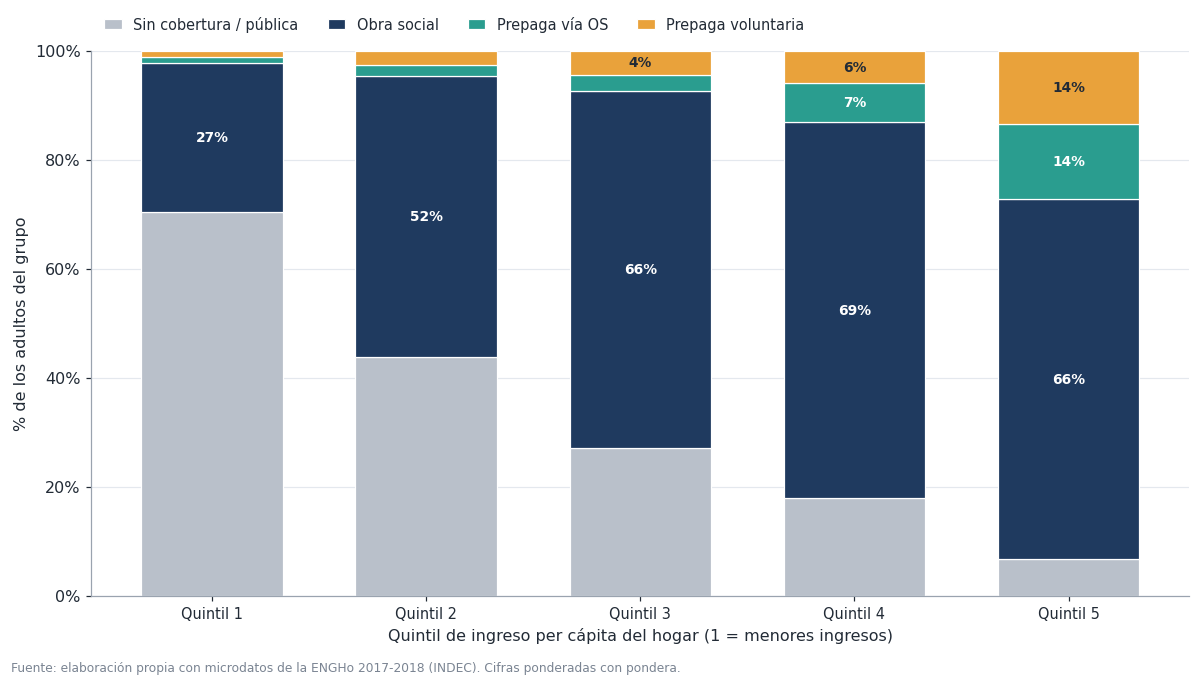

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/M1_composicion_por_quintil.png
Epígrafe sugerido: Cobertura de salud de los adultos según quintil de ingreso per cápita del hogar (%)


cobertura,Sin cobertura / pública,Obra social,Prepaga vía OS,Prepaga voluntaria
quintil,,,,
1,70.5,27.2,1.1,1.2
2,43.8,51.5,2.1,2.6
3,27.1,65.5,3.0,4.4
4,17.9,69.0,7.1,6.0
5,6.8,66.0,13.7,13.5


In [9]:
# ---------- M1. Composición de la cobertura por quintil de ingreso ----------
ct = composicion(df, "quintil", list(range(1, 6)))
barras_apiladas_v(ct, [f"Quintil {q}" for q in ct.index], "Quintil de ingreso per cápita del hogar (1 = menores ingresos)",
                  "M1_composicion_por_quintil", "Composición de la cobertura de salud por quintil de ingreso",
                  "Cobertura de salud de los adultos según quintil de ingreso per cápita del hogar (%)")
display(ct.round(1))

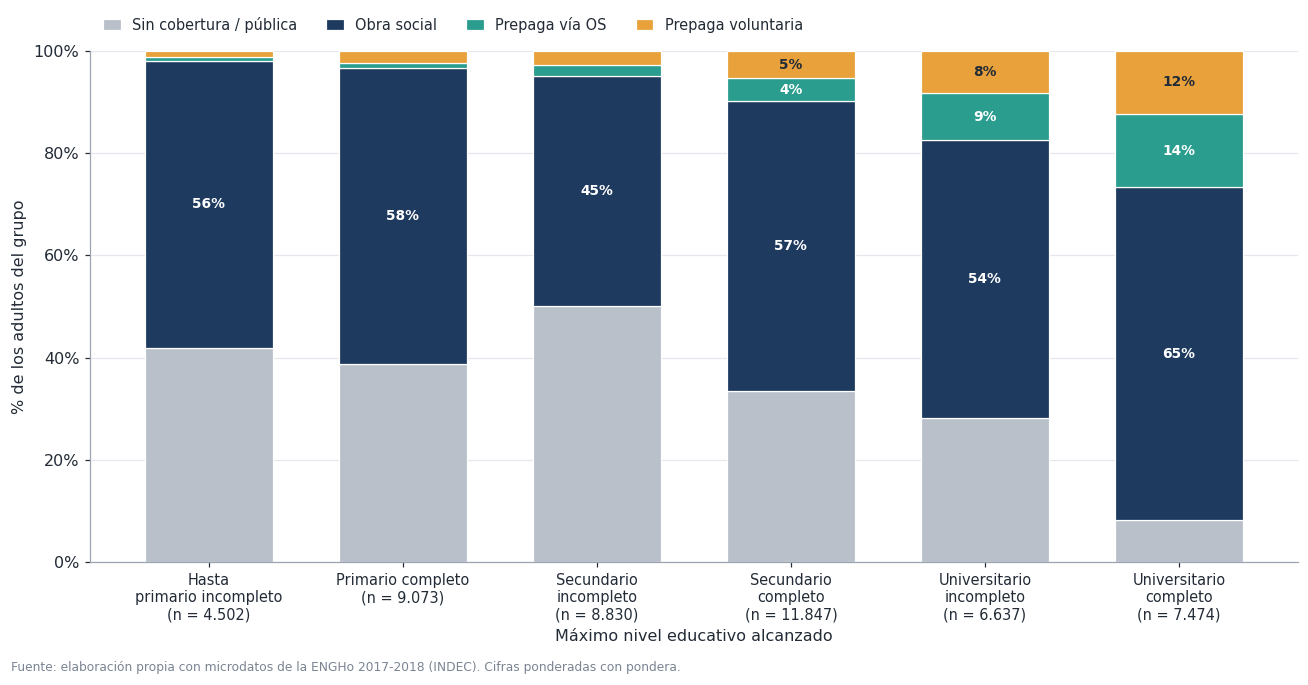

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/M2_composicion_por_educacion.png
Epígrafe sugerido: Cobertura de salud de los adultos según nivel educativo (%)


cobertura,Sin cobertura / pública,Obra social,Prepaga vía OS,Prepaga voluntaria
educ,,,,
1,42.0,56.1,0.7,1.3
2,38.7,57.8,1.0,2.4
3,50.1,45.0,2.1,2.8
4,33.4,56.8,4.5,5.3
5,28.2,54.3,9.3,8.2
6,8.3,65.0,14.4,12.3


In [10]:
# ---------- M2. Composición de la cobertura por nivel educativo ----------
ct = composicion(df, "educ", list(NIV_EDUC))
etq_edu = [NIV_EDUC[k].replace(" ", "\n", 1) if len(NIV_EDUC[k]) > 18 else NIV_EDUC[k] for k in NIV_EDUC]
barras_apiladas_v(ct, [f"{e}\n(n = {miles((df['educ'] == k).sum())})" for e, k in zip(etq_edu, NIV_EDUC)],
                  "Máximo nivel educativo alcanzado", "M2_composicion_por_educacion",
                  "Composición de la cobertura de salud por nivel educativo",
                  "Cobertura de salud de los adultos según nivel educativo (%)", figsize=(12, 6.6))
display(ct.round(1))

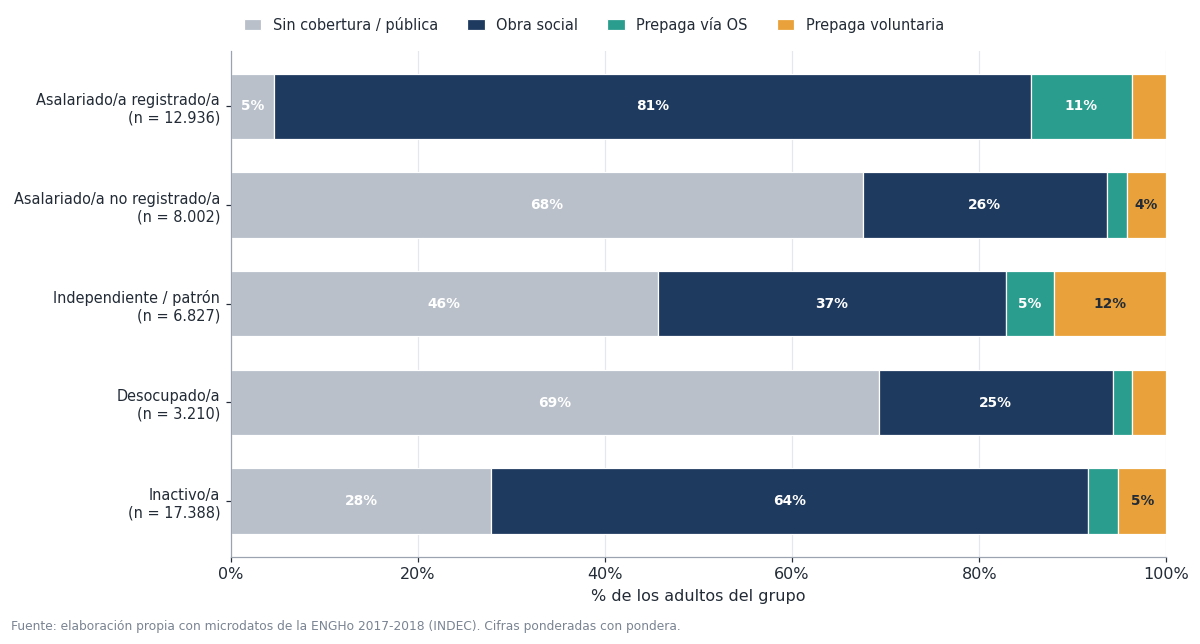

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/M3_composicion_por_condicion_laboral.png
Epígrafe sugerido: Cobertura de salud de los adultos según condición laboral (%)


cobertura,Sin cobertura / pública,Obra social,Prepaga vía OS,Prepaga voluntaria
cond_lab,,,,
asal_reg,4.6,80.9,10.8,3.7
asal_noreg,67.5,26.2,2.1,4.2
indep,45.6,37.2,5.2,12.0
desocupado,69.2,25.0,2.1,3.6
inactivo,27.8,63.8,3.3,5.1


In [11]:
# ---------- M3. Composición de la cobertura por condición laboral ----------
ct = composicion(df, "cond_lab", list(COND_LAB))
ylab = [f"{COND_LAB[k]}\n(n = {miles((df['cond_lab'] == k).sum())})" for k in COND_LAB]
barras_apiladas_h(ct, ylab, "% de los adultos del grupo", "M3_composicion_por_condicion_laboral",
                  "Composición de la cobertura de salud por condición laboral",
                  "Cobertura de salud de los adultos según condición laboral (%)")
display(ct.round(1))

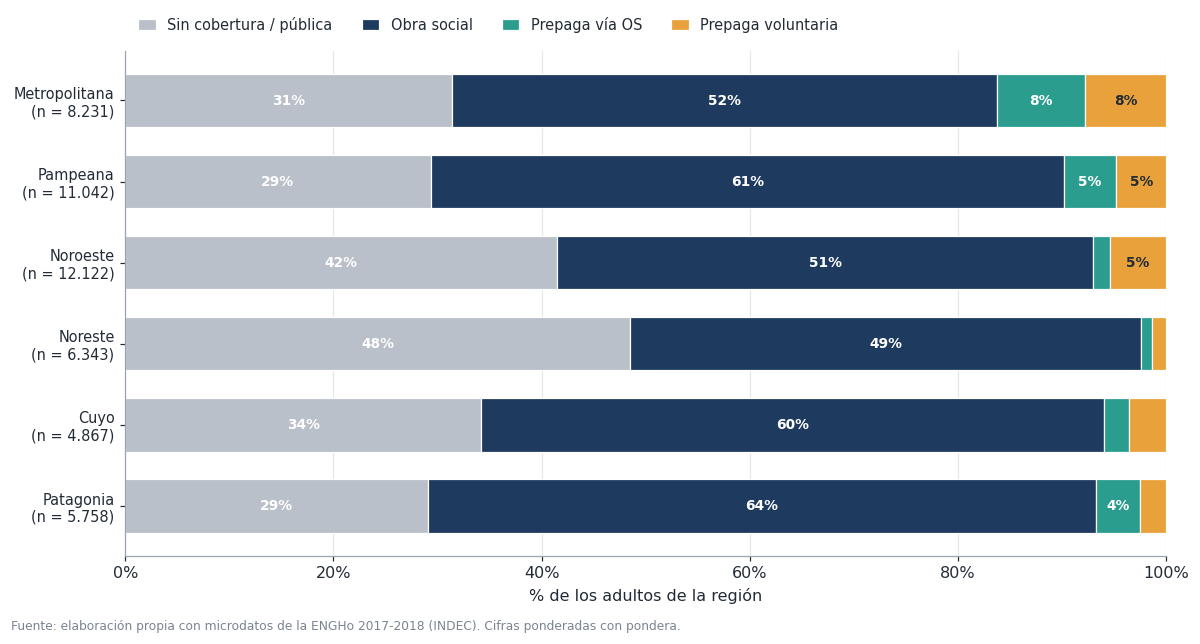

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/M4_composicion_por_region.png
Epígrafe sugerido: Cobertura de salud de los adultos según región estadística (%)


cobertura,Sin cobertura / pública,Obra social,Prepaga vía OS,Prepaga voluntaria
region,,,,
Metropolitana,31.4,52.4,8.4,7.8
Pampeana,29.3,60.8,5.0,4.8
Noroeste,41.5,51.4,1.6,5.4
Noreste,48.5,49.1,1.0,1.4
Cuyo,34.2,59.8,2.3,3.6
Patagonia,29.1,64.2,4.2,2.6


In [12]:
# ---------- M4. Composición de la cobertura por región ----------
orden_reg = list(REGIONES.values())
ct = composicion(df, "region", orden_reg)
ylab = [f"{r}\n(n = {miles((df['region'] == r).sum())})" for r in orden_reg]
barras_apiladas_h(ct, ylab, "% de los adultos de la región", "M4_composicion_por_region",
                  "Composición de la cobertura de salud por región",
                  "Cobertura de salud de los adultos según región estadística (%)")
display(ct.round(1))

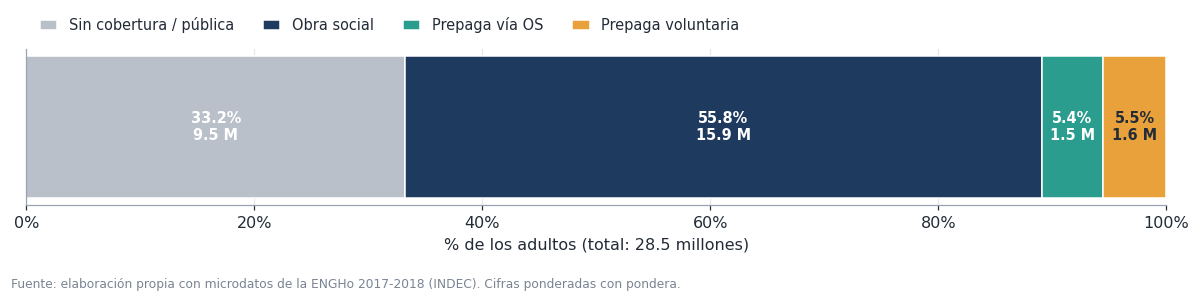

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/M5_mercado_total.png
Epígrafe sugerido: Distribución de los adultos según tipo de cobertura de salud, en porcentaje y millones de personas
{'Sin cobertura / pública': 9.47, 'Obra social': 15.91, 'Prepaga vía OS': 1.54, 'Prepaga voluntaria': 1.58}


In [13]:
# ---------- M5. Composición total del mercado, en millones de adultos ----------
tot = df.groupby("cobertura", observed=True)["pondera"].sum().reindex(ETQ_COB)
pct = tot / tot.sum() * 100
fig, ax = plt.subplots(figsize=(11, 2.9))
izq = 0.0
for g in ETQ_COB:
    ax.barh([0], [pct[g]], left=izq, color=COL[g], height=0.55, edgecolor="white", linewidth=1, label=g)
    color_txt = TINTA if g == ETQ_COB[3] else "white"
    if pct[g] >= 4:
        ax.text(izq + pct[g] / 2, 0, f"{pct[g]:.1f}%\n{tot[g]/1e6:.1f} M", ha="center", va="center",
                fontsize=9.5, color=color_txt, fontweight="bold")
    izq += pct[g]
ax.set_xlim(0, 100)
ax.set_yticks([])
fmt_pct_eje(ax, "x")
ax.set_xlabel(f"% de los adultos (total: {tot.sum()/1e6:.1f} millones)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.02), fontsize=9.5, handlelength=1.2)
encabezado(fig, "Composición del mercado de cobertura de salud")
fig.tight_layout(rect=[0, 0.08, 1, margen_sup(True)])
guardar(fig, "M5_mercado_total", "Distribución de los adultos según tipo de cobertura de salud, en porcentaje y millones de personas")
print((tot / 1e6).round(2).to_dict())

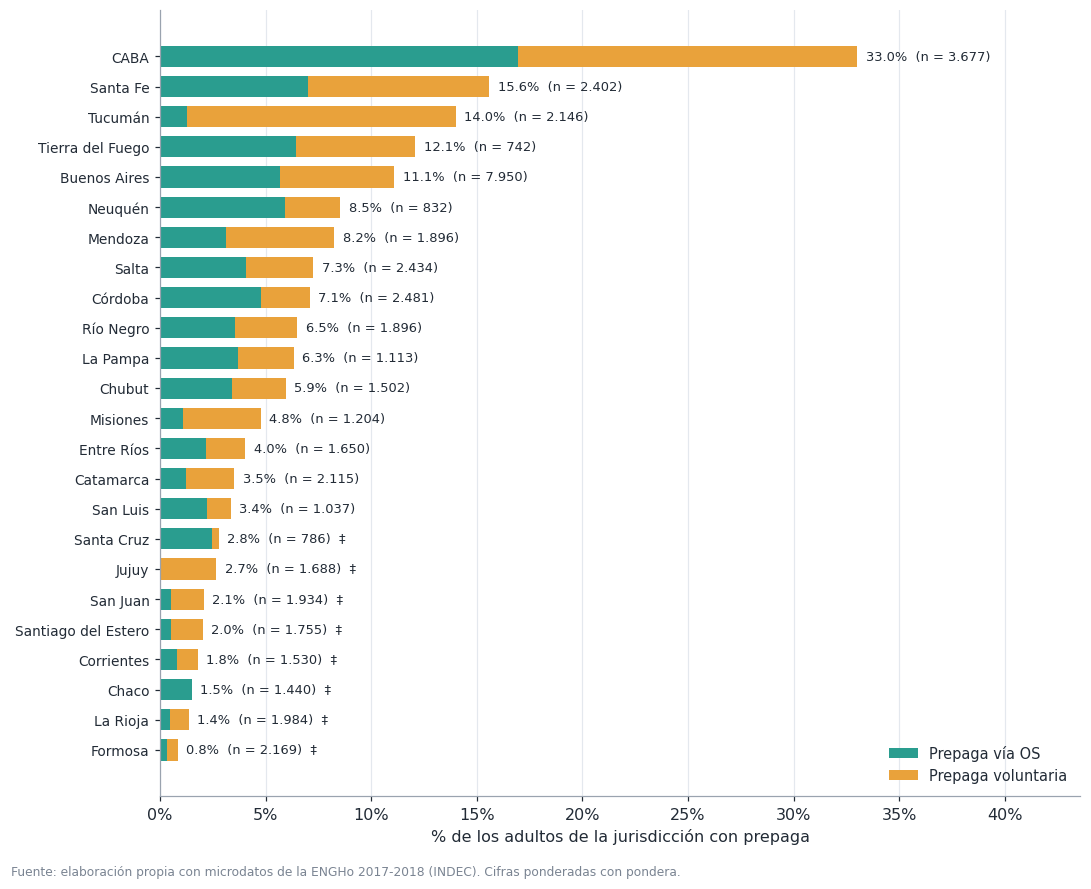

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/M6_prepaga_por_provincia.png
Epígrafe sugerido: Adultos con prepaga (vía obra social o voluntaria) por jurisdicción (%). ‡ marca una proporción menor al 3%, no confiable según el estándar de INDEC


,via,vol,n,total
provincia_nombre,,,,
Formosa,0.3,0.5,2169.0,0.8
La Rioja,0.5,0.9,1984.0,1.4
Chaco,1.5,0.0,1440.0,1.5
Corrientes,0.8,1.0,1530.0,1.8
Santiago del Estero,0.5,1.5,1755.0,2.0
San Juan,0.5,1.5,1934.0,2.1
Jujuy,0.0,2.7,1688.0,2.7
Santa Cruz,2.5,0.3,786.0,2.8
San Luis,2.2,1.1,1037.0,3.4


In [14]:
# ---------- M6. Prepaga total por provincia (barras) ----------
prov = df.groupby("provincia_nombre").apply(
    lambda s: pd.Series({
        "via": pct_pond((s["cobertura"] == ETQ_COB[2]), s["pondera"]),
        "vol": pct_pond((s["cobertura"] == ETQ_COB[3]), s["pondera"]),
        "n": len(s)}))
prov["total"] = prov["via"] + prov["vol"]
prov = prov.sort_values("total")
fig, ax = plt.subplots(figsize=(10, 8.4))
y = np.arange(len(prov))
ax.barh(y, prov["via"], color=COL[ETQ_COB[2]], height=0.7, label=ETQ_COB[2])
ax.barh(y, prov["vol"], left=prov["via"], color=COL[ETQ_COB[3]], height=0.7, label=ETQ_COB[3])
for yi, (t, n) in enumerate(zip(prov["total"], prov["n"])):
    ax.text(t + 0.4, yi, f"{t:.1f}%  (n = {miles(n)})" + ("  ‡" if t < 3 else ""), va="center", fontsize=8.5)
ax.set_yticks(y)
ax.set_yticklabels(prov.index, fontsize=9)
ax.set_xlim(0, prov["total"].max() * 1.32)
fmt_pct_eje(ax, "x")
ax.set_xlabel("% de los adultos de la jurisdicción con prepaga")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=9.5)
encabezado(fig, "Prepaga total por jurisdicción")
fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
guardar(fig, "M6_prepaga_por_provincia", "Adultos con prepaga (vía obra social o voluntaria) por jurisdicción (%). ‡ marca una proporción menor al 3%, no confiable según el estándar de INDEC")
display(prov.round(1))

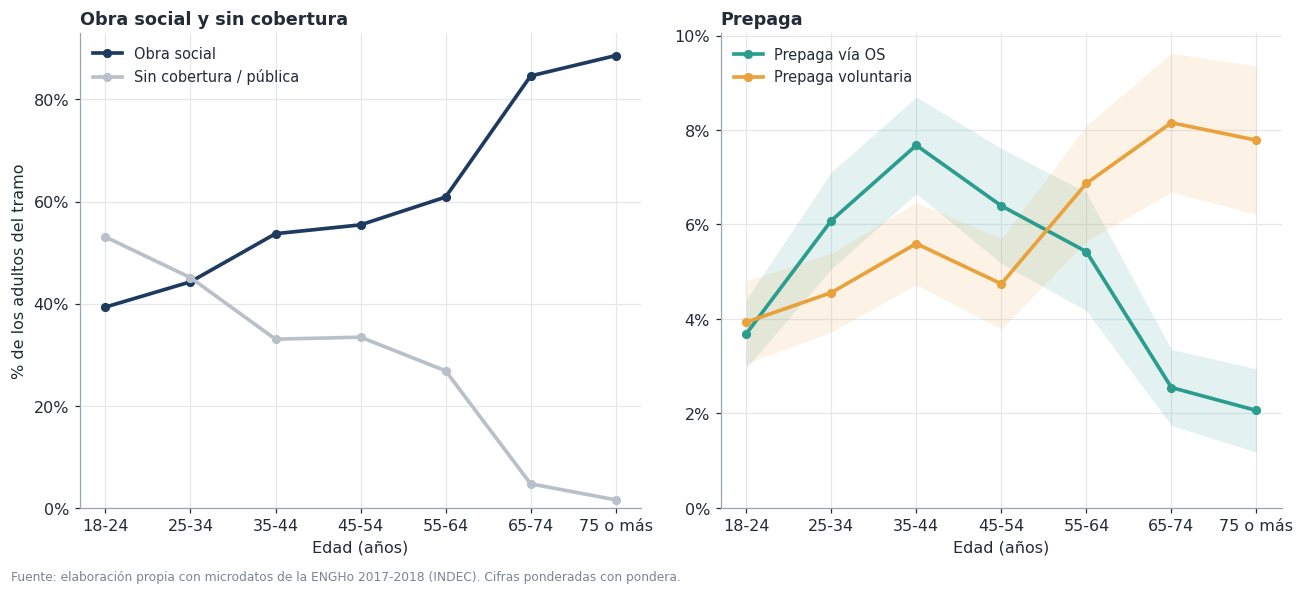

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/M8_cobertura_por_edad.png
Epígrafe sugerido: Tasa de cobertura por tipo según tramo de edad (%), con intervalo de confianza del 95% en las prepagas


In [15]:
# ---------- M8. Cobertura por tramo de edad ----------
cortes = [17, 24, 34, 44, 54, 64, 74, 200]
etq_edad = ["18-24", "25-34", "35-44", "45-54", "55-64", "65-74", "75 o más"]
d_edad = df.assign(tramo=pd.cut(df["edad"], bins=cortes, labels=etq_edad))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
paneles = [([ETQ_COB[1], ETQ_COB[0]], "Obra social y sin cobertura"), ([ETQ_COB[2], ETQ_COB[3]], "Prepaga")]
for ax, (cats, titulo) in zip(axes, paneles):
    for cob in cats:
        t = tasas(d_edad, "tramo", cob)
        ax.plot(range(len(t)), t["pct"], marker="o", ms=5, lw=2.4, color=COL[cob], label=cob)
        if cob in ETQ_COB[2:]:
            ax.fill_between(range(len(t)), t["lo"], t["hi"], color=COL[cob], alpha=0.13, lw=0)
    ax.set_xticks(range(len(etq_edad)))
    ax.set_xticklabels(etq_edad)
    ax.set_xlabel("Edad (años)")
    ax.set_title(titulo, loc="left", fontweight="bold")
    fmt_pct_eje(ax)
    ax.set_ylim(bottom=0)
    ax.legend(loc="best", fontsize=9.5)
axes[0].set_ylabel("% de los adultos del tramo")
encabezado(fig, "Cobertura de salud por tramo de edad")
fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
guardar(fig, "M8_cobertura_por_edad", "Tasa de cobertura por tipo según tramo de edad (%), con intervalo de confianza del 95% en las prepagas")

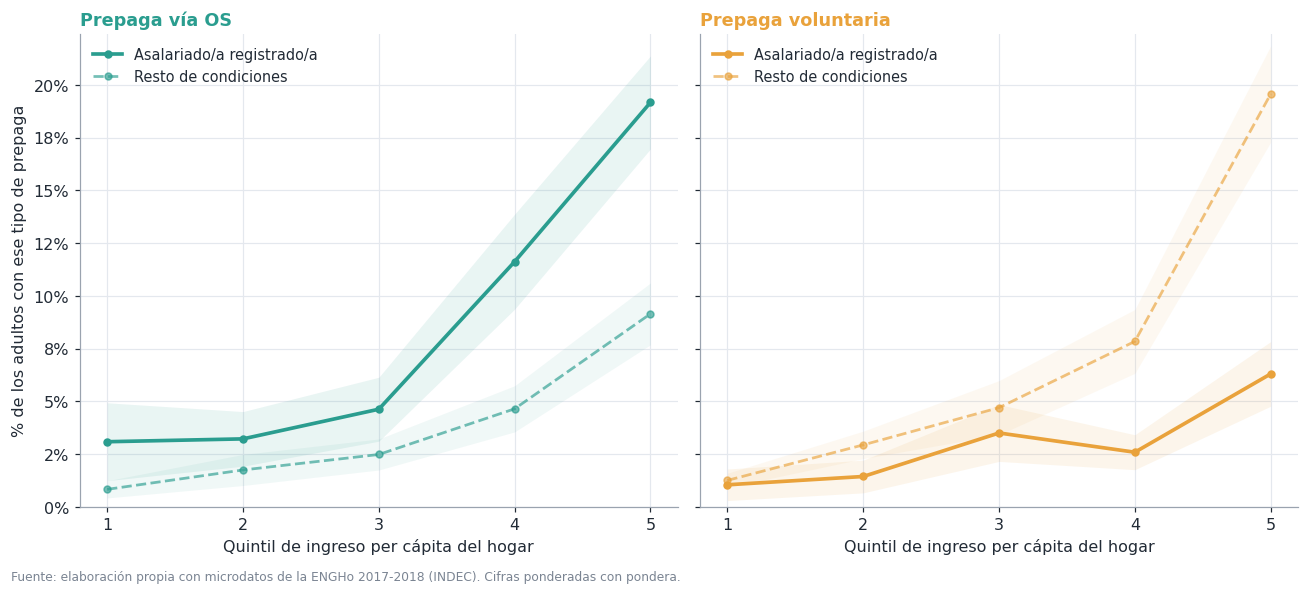

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/M9_prepaga_por_quintil_y_condicion_laboral.png
Epígrafe sugerido: Tasa de prepaga vía OS y voluntaria por quintil de ingreso, según el adulto sea asalariado registrado o no (%), con IC del 95%


In [16]:
# ---------- M9. Tasa de prepaga por quintil según condición laboral ----------
df["grupo_lab"] = np.where(df["cond_lab"] == "asal_reg", "Asalariado/a registrado/a", "Resto de condiciones")
ESTILO_LAB = {"Asalariado/a registrado/a": ("-", 2.4, 1.0), "Resto de condiciones": ("--", 1.8, 0.65)}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), sharey=True)
for ax, cob in zip(axes, [ETQ_COB[2], ETQ_COB[3]]):
    for grupo, (ls, lw, alfa) in ESTILO_LAB.items():
        t = tasas(df[df["grupo_lab"] == grupo], "quintil", cob).reindex(range(1, 6))
        ax.plot(t.index, t["pct"], ls=ls, lw=lw, marker="o", ms=4.5, color=COL[cob], alpha=alfa, label=grupo)
        ax.fill_between(t.index, t["lo"], t["hi"], color=COL[cob], alpha=0.10 * alfa, lw=0)
    ax.set_title(cob, loc="left", fontweight="bold", color=COL[cob])
    ax.set_xticks(range(1, 6))
    ax.set_xlabel("Quintil de ingreso per cápita del hogar")
    fmt_pct_eje(ax)
    ax.set_ylim(bottom=0)
    ax.legend(loc="upper left", fontsize=9.5)
axes[0].set_ylabel("% de los adultos con ese tipo de prepaga")
encabezado(fig, "Tasa de cada tipo de prepaga por quintil de ingreso, según condición laboral")
fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
guardar(fig, "M9_prepaga_por_quintil_y_condicion_laboral", "Tasa de prepaga vía OS y voluntaria por quintil de ingreso, según el adulto sea asalariado registrado o no (%), con IC del 95%")

### Gráficos de contraste entre prepaga vía OS y prepaga voluntaria (V1 a V8)

Los gráficos V1, V4, V5 y V6 muestran el **perfil** de cada tipo: de cada 100 adultos con prepaga vía OS (o voluntaria), cuántos pertenecen a cada categoría. Los gráficos V2 y V3 muestran la **tasa inversa**: dentro de cada categoría, qué porcentaje de las prepagas es voluntaria.

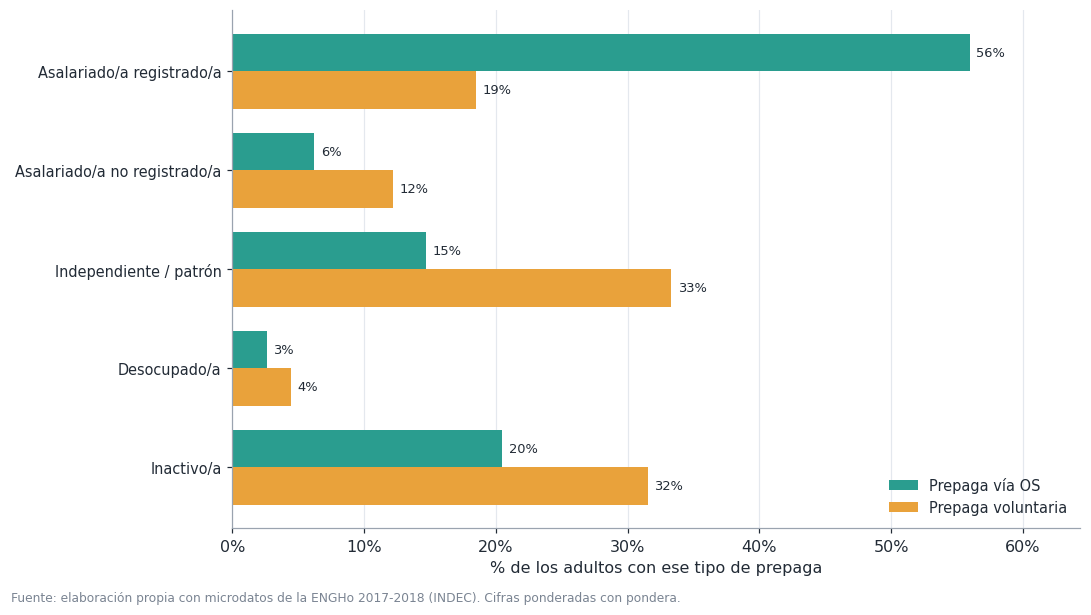

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/V1_perfil_laboral_por_tipo.png
Epígrafe sugerido: Condición laboral de los adultos con prepaga vía OS y con prepaga voluntaria (% de cada tipo)


cobertura,Prepaga vía OS,Prepaga voluntaria
cond_lab,,
asal_reg,56.0,18.5
asal_noreg,6.2,12.2
indep,14.7,33.3
desocupado,2.6,4.4
inactivo,20.5,31.5


In [17]:
TIPOS = ETQ_COB[2:]
COLOR_TIPO = {t: COL[t] for t in TIPOS}

def perfil_barras(var, orden, etiquetas, xlabel, nombre, titulo, epigrafe, horizontal=True, figsize=(10, 5.8)):
    t = dprep.pivot_table(index=var, columns="cobertura", values="pondera", aggfunc="sum", observed=True)[TIPOS].reindex(orden)
    t = t.div(t.sum(axis=0), axis=1) * 100
    fig, ax = plt.subplots(figsize=figsize)
    pos = np.arange(len(t))
    ancho = 0.38
    for i, tipo in enumerate(TIPOS):
        desp = (i - 0.5) * ancho
        if horizontal:
            ax.barh(len(t) - 1 - pos + desp * -1, t[tipo], height=ancho, color=COLOR_TIPO[tipo], label=tipo)
            for yv, v in zip(len(t) - 1 - pos + desp * -1, t[tipo]):
                ax.text(v + 0.5, yv, f"{v:.0f}%", va="center", fontsize=8.5)
        else:
            ax.bar(pos + desp, t[tipo], width=ancho, color=COLOR_TIPO[tipo], label=tipo)
            for xv, v in zip(pos + desp, t[tipo]):
                ax.text(xv, v + 0.6, f"{v:.0f}%", ha="center", fontsize=8.5)
    if horizontal:
        ax.set_yticks(len(t) - 1 - pos)
        ax.set_yticklabels(etiquetas, fontsize=9.5)
        fmt_pct_eje(ax, "x")
        ax.set_xlabel(xlabel)
        ax.set_xlim(0, t.values.max() * 1.15)
        ax.grid(axis="y", visible=False)
    else:
        ax.set_xticks(pos)
        ax.set_xticklabels(etiquetas, fontsize=9.5)
        fmt_pct_eje(ax)
        ax.set_ylabel(xlabel)
        ax.set_ylim(0, t.values.max() * 1.15)
        ax.grid(axis="x", visible=False)
    ax.legend(loc="lower right" if horizontal else "upper left", fontsize=9.5)
    encabezado(fig, titulo, "Adultos con prepaga (N = " + miles(len(dprep)) + ")")
    fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
    guardar(fig, nombre, epigrafe)
    return t

# ---------- V1. Perfil laboral de cada tipo de prepaga ----------
t = perfil_barras("cond_lab", list(COND_LAB), list(COND_LAB.values()), "% de los adultos con ese tipo de prepaga",
                  "V1_perfil_laboral_por_tipo", "Perfil laboral de cada tipo de prepaga",
                  "Condición laboral de los adultos con prepaga vía OS y con prepaga voluntaria (% de cada tipo)")
display(t.round(1))

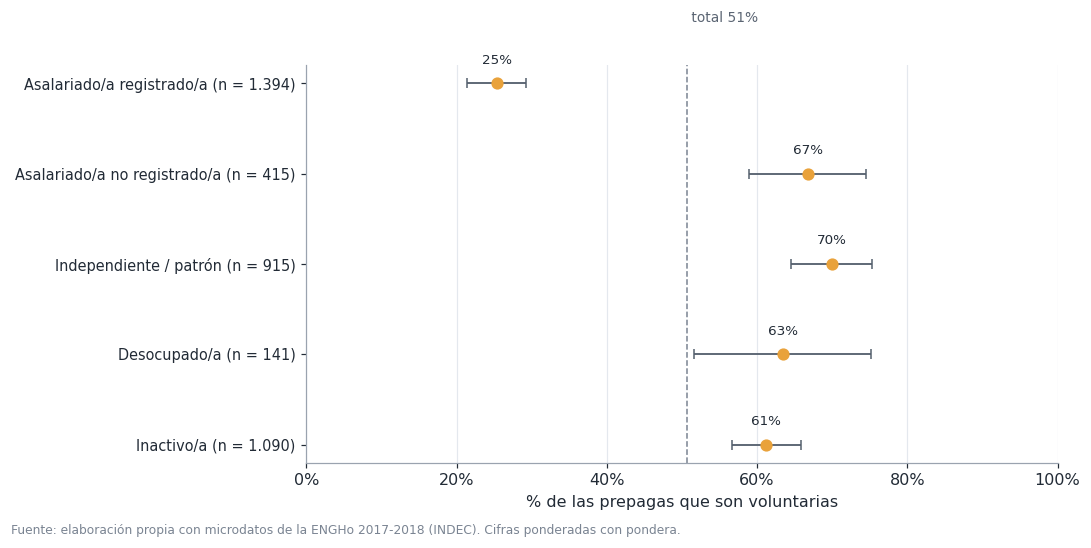

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/V2_peso_voluntaria_por_condicion_laboral.png
Epígrafe sugerido: Porcentaje de las prepagas que son voluntarias, según condición laboral, con IC del 95%


,pct,lo,hi
asal_reg,25.3,21.4,29.2
asal_noreg,66.7,59.0,74.5
indep,69.9,64.5,75.4
desocupado,63.4,51.7,75.2
inactivo,61.2,56.6,65.8


In [18]:
# ---------- V2. Peso de la voluntaria dentro de la prepaga, por condición laboral ----------
def puntos_ic(t, etiquetas, xlabel, nombre, titulo, epigrafe, ref=None, ns=None, figsize=(10, 5.2)):
    fig, ax = plt.subplots(figsize=figsize)
    y = np.arange(len(t))[::-1]
    err = np.array([t["pct"] - t["lo"], t["hi"] - t["pct"]])
    ax.errorbar(t["pct"], y, xerr=err, fmt="o", color=COL[ETQ_COB[3]], ecolor="#55606E", elinewidth=1.2, capsize=3, ms=7)
    if ref is not None:
        ax.axvline(ref, color="#7A8492", lw=1, ls="--")
        ax.text(ref, len(t) - 0.35, f" total {ref:.0f}%", color="#5B6573", fontsize=9, va="bottom")
    for yi, v in zip(y, t["pct"]):
        ax.text(v, yi + 0.22, f"{v:.0f}%", ha="center", fontsize=8.8)
    ax.set_yticks(y)
    ax.set_yticklabels(etiquetas, fontsize=9.5)
    ax.set_xlim(0, 100)
    fmt_pct_eje(ax, "x")
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    encabezado(fig, titulo, "Adultos con prepaga (N = " + miles(len(dprep)) + ")")
    fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
    guardar(fig, nombre, epigrafe)

peso_total = pct_pond((dprep["cobertura"] == ETQ_COB[3]), dprep["pondera"])
t = tasas(dprep, "cond_lab", ETQ_COB[3]).reindex(list(COND_LAB))
etq = [f"{COND_LAB[k]} (n = {miles((dprep['cond_lab'] == k).sum())})" for k in COND_LAB]
puntos_ic(t, etq, "% de las prepagas que son voluntarias", "V2_peso_voluntaria_por_condicion_laboral",
          "Peso de la prepaga voluntaria dentro de la prepaga, por condición laboral",
          "Porcentaje de las prepagas que son voluntarias, según condición laboral, con IC del 95%", ref=peso_total)
display(t.round(1))

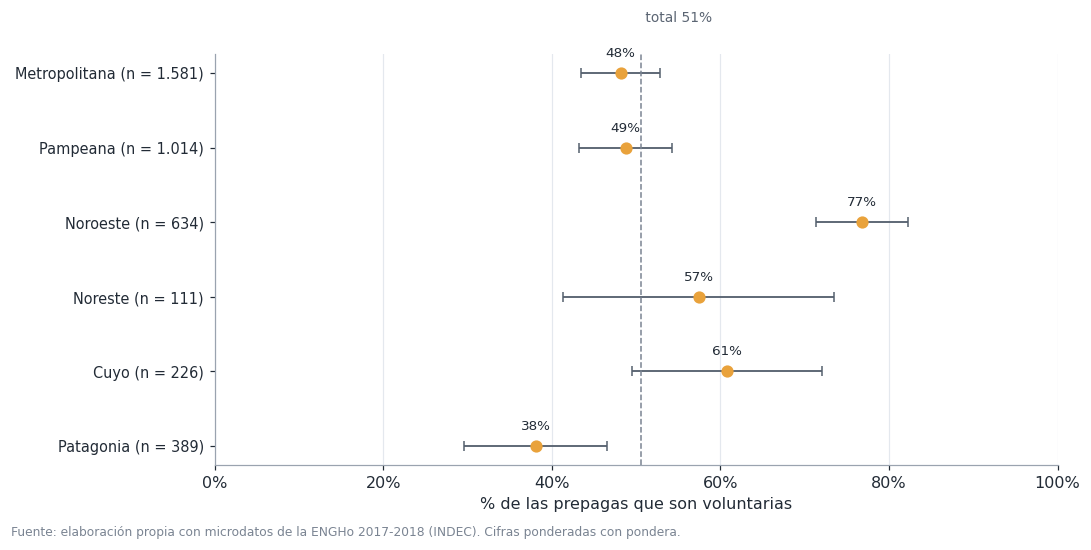

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/V3_peso_voluntaria_por_region.png
Epígrafe sugerido: Porcentaje de las prepagas que son voluntarias, según región, con IC del 95%. Las celdas de las regiones Noreste y Cuyo son chicas


,pct,lo,hi
Metropolitana,48.2,43.5,52.8
Pampeana,48.8,43.2,54.3
Noroeste,76.8,71.3,82.3
Noreste,57.4,41.4,73.4
Cuyo,60.8,49.5,72.1
Patagonia,38.1,29.6,46.6


In [19]:
# ---------- V3. Peso de la voluntaria dentro de la prepaga, por región ----------
t = tasas(dprep, "region", ETQ_COB[3]).reindex(orden_reg)
etq = [f"{r} (n = {miles((dprep['region'] == r).sum())})" for r in orden_reg]
puntos_ic(t, etq, "% de las prepagas que son voluntarias", "V3_peso_voluntaria_por_region",
          "Peso de la prepaga voluntaria dentro de la prepaga, por región",
          "Porcentaje de las prepagas que son voluntarias, según región, con IC del 95%. Las celdas de las regiones Noreste y Cuyo son chicas", ref=peso_total)
display(t.round(1))

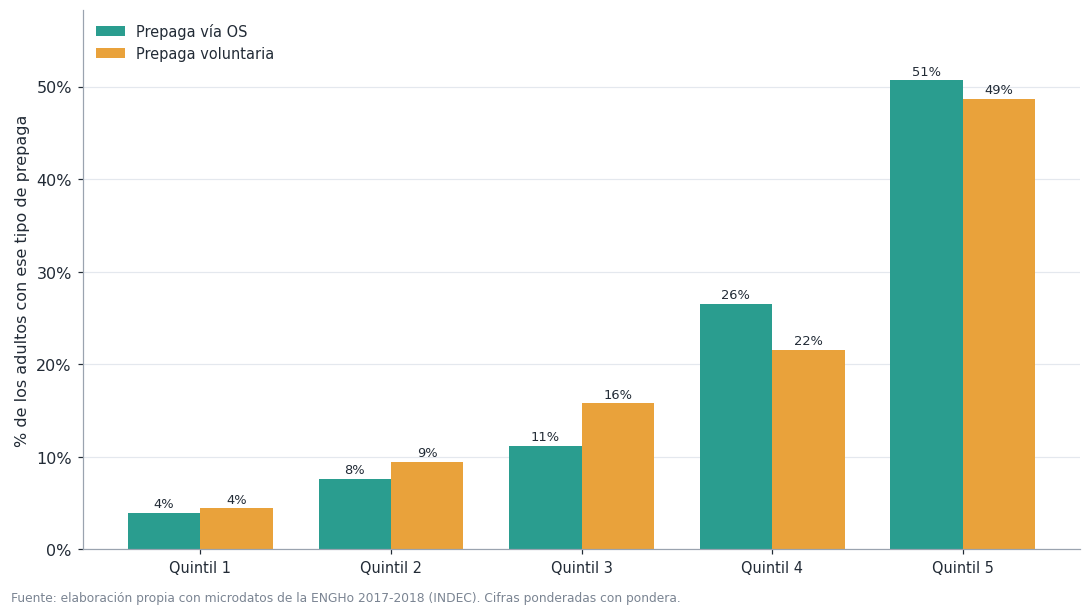

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/V4_perfil_por_quintil_por_tipo.png
Epígrafe sugerido: Distribución por quintil de ingreso per cápita del hogar de los adultos con prepaga vía OS y voluntaria (% de cada tipo)


cobertura,Prepaga vía OS,Prepaga voluntaria
quintil,,
1,4.0,4.4
2,7.6,9.5
3,11.2,15.8
4,26.5,21.6
5,50.7,48.7


In [20]:
# ---------- V4. Perfil por quintil de cada tipo de prepaga ----------
t = perfil_barras("quintil", list(range(1, 6)), [f"Quintil {q}" for q in range(1, 6)], "% de los adultos con ese tipo de prepaga",
                  "V4_perfil_por_quintil_por_tipo", "Perfil por quintil de ingreso de cada tipo de prepaga",
                  "Distribución por quintil de ingreso per cápita del hogar de los adultos con prepaga vía OS y voluntaria (% de cada tipo)",
                  horizontal=False)
display(t.round(1))

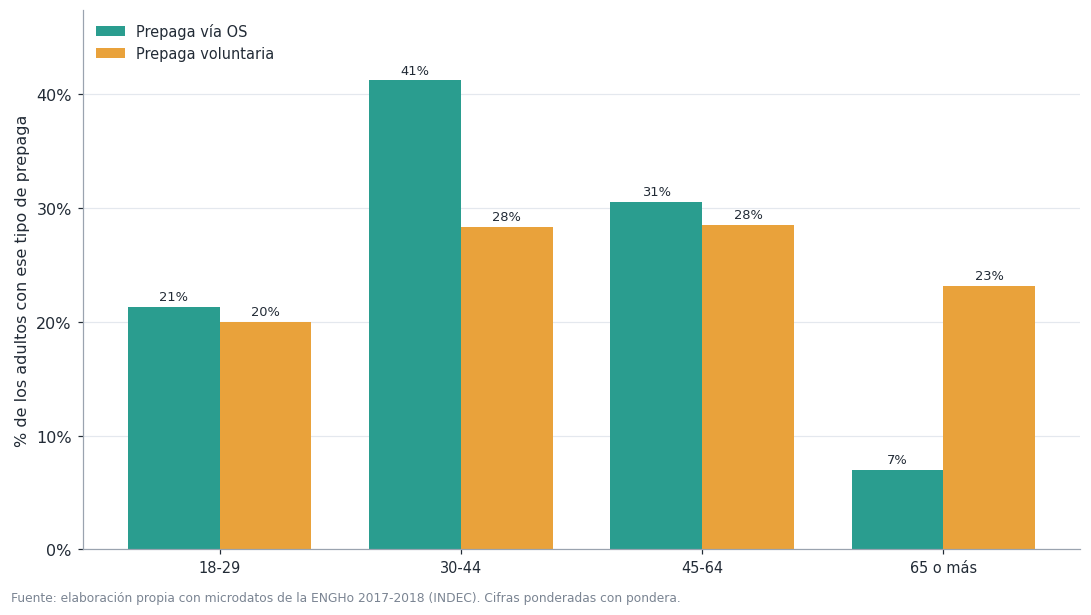

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/V5_perfil_por_edad_por_tipo.png
Epígrafe sugerido: Distribución por tramo de edad de los adultos con prepaga vía OS y voluntaria (% de cada tipo)


cobertura,Prepaga vía OS,Prepaga voluntaria
tramo4,,
18-29,21.3,20.0
30-44,41.2,28.3
45-64,30.5,28.5
65 o más,7.0,23.2


In [21]:
# ---------- V5. Perfil por tramo de edad de cada tipo de prepaga ----------
dprep["tramo4"] = pd.cut(dprep["edad"], bins=[17, 29, 44, 64, 200], labels=["18-29", "30-44", "45-64", "65 o más"])
t = perfil_barras("tramo4", ["18-29", "30-44", "45-64", "65 o más"], ["18-29", "30-44", "45-64", "65 o más"],
                  "% de los adultos con ese tipo de prepaga", "V5_perfil_por_edad_por_tipo",
                  "Perfil por edad de cada tipo de prepaga",
                  "Distribución por tramo de edad de los adultos con prepaga vía OS y voluntaria (% de cada tipo)", horizontal=False)
display(t.round(1))

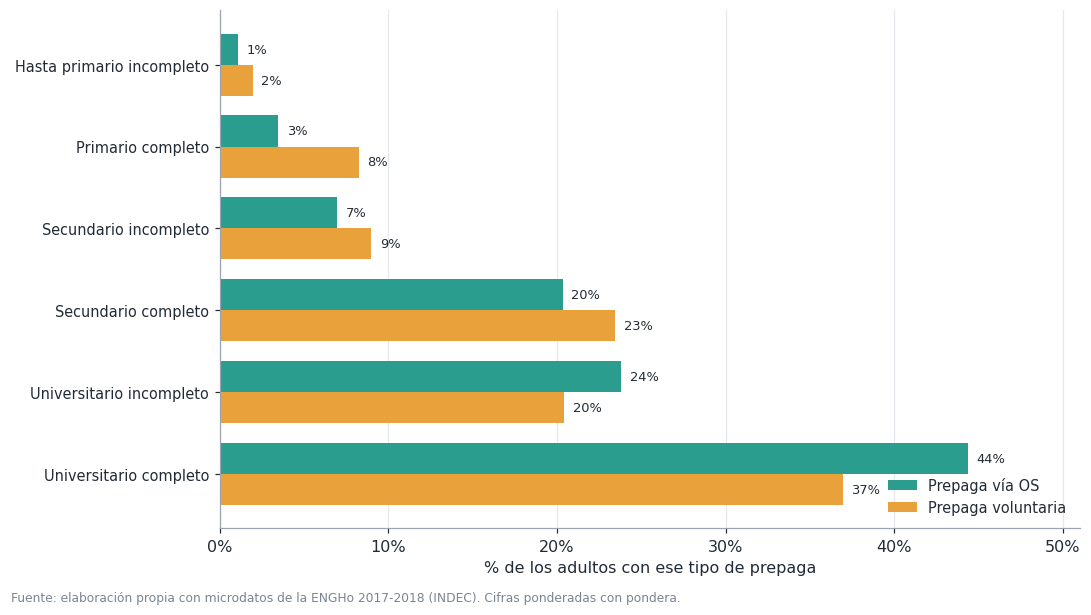

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/V6_perfil_educativo_por_tipo.png
Epígrafe sugerido: Nivel educativo de los adultos con prepaga vía OS y voluntaria (% de cada tipo)


cobertura,Prepaga vía OS,Prepaga voluntaria
educ,,
1,1.1,1.9
2,3.5,8.2
3,6.9,9.0
4,20.4,23.5
5,23.8,20.4
6,44.4,37.0


In [22]:
# ---------- V6. Perfil educativo de cada tipo de prepaga ----------
t = perfil_barras("educ", list(NIV_EDUC), [NIV_EDUC[k] for k in NIV_EDUC], "% de los adultos con ese tipo de prepaga",
                  "V6_perfil_educativo_por_tipo", "Perfil educativo de cada tipo de prepaga",
                  "Nivel educativo de los adultos con prepaga vía OS y voluntaria (% de cada tipo)")
display(t.round(1))

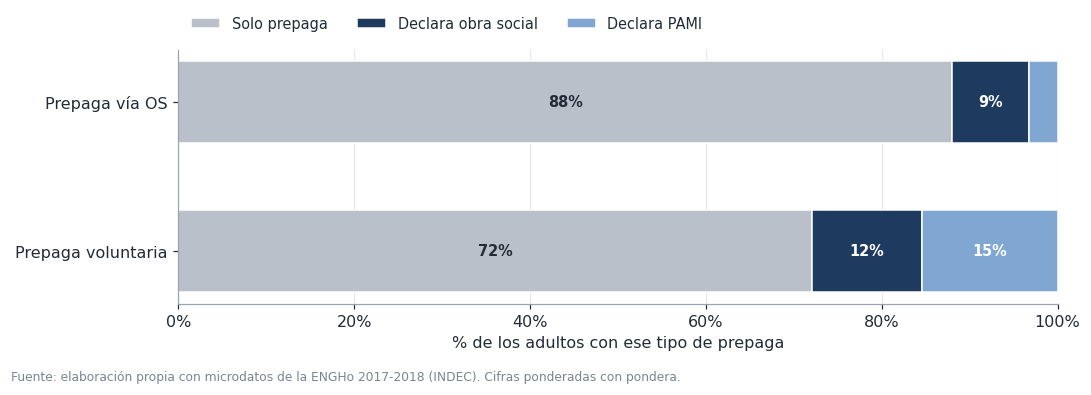

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/V8_otras_coberturas_en_prepaga.png
Epígrafe sugerido: Otras coberturas declaradas por los adultos con prepaga vía OS y voluntaria (% de cada tipo). La prepaga vía OS supone un vínculo con una obra social


otra_cob,Solo prepaga,Declara obra social,Declara PAMI
cobertura,,,
Prepaga vía OS,88.0,8.8,3.2
Prepaga voluntaria,72.1,12.5,15.5


In [23]:
# ---------- V8. Otras coberturas declaradas por quienes tienen prepaga ----------
dprep["otra_cob"] = np.select([dprep["pami"] == 1, dprep["cp23_02"] == 1], ["Declara PAMI", "Declara obra social"], "Solo prepaga")
ORD_OTRA = ["Solo prepaga", "Declara obra social", "Declara PAMI"]
col_otra = {"Solo prepaga": "#B9C0CA", "Declara obra social": COL[ETQ_COB[1]], "Declara PAMI": "#7FA7D1"}
t = dprep.pivot_table(index="cobertura", columns="otra_cob", values="pondera", aggfunc="sum", observed=True)[ORD_OTRA].reindex(TIPOS)
t = t.div(t.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 3.8))
ypos = np.arange(len(t))[::-1]
izq = np.zeros(len(t))
for c in ORD_OTRA:
    ax.barh(ypos, t[c].values, left=izq, color=col_otra[c], height=0.55, edgecolor="white", label=c)
    for yv, b0, v in zip(ypos, izq, t[c].values):
        if v >= 4:
            ax.text(b0 + v / 2, yv, f"{v:.0f}%", ha="center", va="center", fontsize=9.5,
                    color="white" if c != "Solo prepaga" else TINTA, fontweight="bold")
    izq += t[c].values
ax.set_yticks(ypos)
ax.set_yticklabels(TIPOS)
ax.set_xlim(0, 100)
fmt_pct_eje(ax, "x")
ax.set_xlabel("% de los adultos con ese tipo de prepaga")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.02), fontsize=9.5)
encabezado(fig, "Otras coberturas declaradas por quienes tienen prepaga", "Adultos con prepaga (N = " + miles(len(dprep)) + ")")
fig.tight_layout(rect=[0, 0.05, 1, margen_sup(True)])
guardar(fig, "V8_otras_coberturas_en_prepaga", "Otras coberturas declaradas por los adultos con prepaga vía OS y voluntaria (% de cada tipo). La prepaga vía OS supone un vínculo con una obra social")
display(t.round(1))

## Módulo 7. Estimaciones econométricas

Todos los modelos son **logit estimados por máxima verosimilitud ponderada con `pondera`** (pseudoverosimilitud, sin normalizar el factor de expansión). Los **errores estándar salen de las 200 réplicas bootstrap de INDEC**: cada modelo se estima con `pondera` y con cada réplica, y el error de cualquier resultado (coeficiente, odds ratio, efecto marginal, elasticidad) es la raíz del promedio de los cuadrados de las diferencias entre cada réplica y la estimación completa (`error_replicas`, Módulo 1). Un único motor, escrito con `numpy`, estima tanto el logit binario como el multinomial (el binario es el caso de dos categorías). Antes de usarlo se valida contra `scikit-learn`.

Tres estimaciones, que responden a tres preguntas:

| Bloque | Modelo | Pregunta |
|---|---|---|
| **A** | Logit sobre `prepaga_total`, dos especificaciones | ¿Qué se asocia con tener una prepaga? |
| **B** | Logit multinomial de `cobertura` (referencia: sin cobertura / pública) | ¿Cómo se reparten los adultos entre las cuatro coberturas? |
| **C** | Logit de prepaga voluntaria (1) frente a prepaga vía OS (0), solo entre quienes tienen prepaga | ¿Qué distingue a la compra directa de la prepaga institucional? |

**Especificaciones del bloque A.**

| Modelo | Especificación |
|---|---|
| A1 | `log_ingpch` |
| A3 | A1 + edad, edad², mujer, dificultad de largo plazo, educación, condición laboral, jubilado/a y región |

Los bloques B y C usan la especificación A3.

**Efectos marginales.** Se calculan a mano (promedio ponderado con `pondera` sobre la muestra). Para variables binarias y categóricas es el cambio en la probabilidad al pasar de 0 a 1 (o de la categoría de referencia a la categoría), y para variables continuas es la derivada. Se agregan dos efectos fáciles de leer: **duplicar el ingreso** y **+10 años de edad**. Se expresan en puntos porcentuales (p.p.). Su error estándar sale de las réplicas.

**Lectura del ingreso.** En un logit, el coeficiente de `log_ingpch` es una semielasticidad del *log-odds*, no una elasticidad de la demanda. La **elasticidad de la probabilidad** se aproxima con la derivada del efecto marginal dividida por la tasa media ponderada de la categoría (ε = AME / tasa media).

**Ajuste.** Se reportan el pseudo-R² de McFadden (con la pseudoverosimilitud ponderada) y el AUC ponderado (en el multinomial, el promedio de "una categoría contra el resto"). Son cifras descriptivas, sin error estándar.

In [24]:
BIN_COLS = ["mujer", "dificultad", "jubilado"]

LAB = {
    "log_ingpch": "Log(ingreso per cápita del hogar)", "log_ingtotp": "Log(ingreso individual)",
    "edad": "Edad", "edad2": "Edad² / 100", "mujer": "Mujer (=1)",
    "dificultad": "Dificultad de largo plazo (=1)", "jubilado": "Percibe jubilación/pensión (=1)",
}
def etiqueta(col):
    if col in LAB:
        return LAB[col]
    if col.startswith("educ_"):
        return "Educación: " + NIV_EDUC[int(col[5:])]
    if col.startswith("cond_lab_"):
        return "Condición laboral: " + COND_LAB[col[9:]]
    if col.startswith("region_"):
        return "Región: " + col[7:]
    return col

def construir_X(d, cont, cats):
    X = d[cont].astype(float).copy()
    grupos = {}
    for var, ref in cats:
        dm = pd.get_dummies(d[var].astype(str), prefix=var, dtype=float)
        dm = dm.drop(columns=f"{var}_{ref}")
        grupos[var] = list(dm.columns)
        X = pd.concat([X, dm], axis=1)
    X.insert(0, "const", 1.0)
    return X, grupos

# ---------- Especificaciones ----------
CONT_A2 = ["log_ingpch", "edad", "edad2", "mujer", "dificultad"]
CONT_A3 = CONT_A2 + ["jubilado"]
CATS_A2 = [("educ", 1)]
CATS_A3 = CATS_A2 + [("cond_lab", "asal_reg"), ("region", "Metropolitana")]

ESPEC = {
    "A1": (["log_ingpch"], []),
    "A3": (CONT_A3, CATS_A3),
}

### Motor de estimación: logit ponderado

`mnl_ponderado` maximiza la pseudoverosimilitud ponderada por Newton-Raphson con gradiente y hessiano analíticos (con reducción de paso si la verosimilitud no mejora). Las tolerancias son relativas al tamaño de la verosimilitud, porque con `pondera` sin normalizar la verosimilitud es muy grande. La categoría base es la 0. Con dos categorías es el logit binario. El motor devuelve los coeficientes, la verosimilitud y si convergió; el error estándar lo da `error_replicas`.

In [25]:
def _probs(S):
    # S: puntajes lineales (n x (J-1)). Softmax con categoría base = 0 (para J = 2 es la sigmoide).
    Z = np.hstack([np.zeros((S.shape[0], 1)), S])
    Z -= Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def _loglik(B, X, yv, w):
    P = _probs(X @ B)
    return float(np.sum(w * np.log(np.clip(P[np.arange(len(yv)), yv], 1e-300, None))))

def _grad_hess(B, X, Y, w):
    n, K = X.shape
    Jm1 = B.shape[1]
    P = _probs(X @ B)
    R = (Y[:, 1:] - P[:, 1:]) * w[:, None]                      # puntajes por observación y categoría
    grad = (X.T @ R).ravel(order="F")
    H = np.zeros((K * Jm1, K * Jm1))
    for j in range(Jm1):
        for k in range(j, Jm1):
            wjk = w * P[:, j + 1] * ((1.0 if j == k else 0.0) - P[:, k + 1])
            Hjk = -(X.T * wjk) @ X
            H[j * K:(j + 1) * K, k * K:(k + 1) * K] = Hjk
            if k != j:
                H[k * K:(k + 1) * K, j * K:(j + 1) * K] = Hjk.T
    return grad, H, R

def mnl_ponderado(X, yv, w, J, maxit=100):
    # Devuelve B (K x (J-1)), log-verosimilitud ponderada y si el algoritmo convergió.
    Xv = X.values if hasattr(X, "values") else X
    n, K = Xv.shape
    Jm1 = J - 1
    Y = np.eye(J)[yv]
    B = np.zeros((K, Jm1))
    ll = _loglik(B, Xv, yv, w)
    for _ in range(maxit):
        g, H, _r = _grad_hess(B, Xv, Y, w)
        delta = np.linalg.solve(H, g)
        t = 1.0
        while True:
            Bn = B - t * delta.reshape(K, Jm1, order="F")
            lln = _loglik(Bn, Xv, yv, w)
            if lln >= ll - 1e-12 * abs(ll) or t < 1e-6:
                break
            t /= 2
        B, ll = Bn, lln
        if np.max(np.abs(t * delta)) < 1e-9:
            return B, ll, True
    return B, ll, False

### Motor de efectos marginales

Las funciones siguientes calculan los efectos marginales promedio (ponderados) y sus errores estándar. Cada contraste se define como un cambio en las columnas de la matriz de diseño. La probabilidad se evalúa con el cambio y sin él, y se promedia con los pesos. Sirve igual para el logit binario y el multinomial, y el error estándar sale de repetir el cálculo con cada réplica.

In [26]:
def contrastes(X, grupos, ing_col):
    n = len(X)
    idx = {c: i for i, c in enumerate(X.columns)}
    v = X.values
    C = {}
    h = 1e-4

    def edad_cambio(delta):
        e = X["edad"].values
        return {idx["edad"]: np.full(n, delta), idx["edad2"]: ((e + delta) ** 2 - e ** 2) / 100}

    C[etiqueta(ing_col) + " (derivada)"] = ({idx[ing_col]: np.full(n, h)}, {idx[ing_col]: np.full(n, -h)}, 2 * h)
    C["Duplicar el ingreso"] = ({idx[ing_col]: np.full(n, np.log(2))}, {}, 1.0)
    if "edad" in idx:
        C["Edad (derivada, por año)"] = (edad_cambio(h), edad_cambio(-h), 2 * h)
        C["+10 años de edad"] = (edad_cambio(10), {}, 1.0)
    for c in BIN_COLS:
        if c in idx:
            C[etiqueta(c)] = ({idx[c]: 1 - v[:, idx[c]]}, {idx[c]: -v[:, idx[c]]}, 1.0)
    for var, cols in grupos.items():
        for c in cols:
            d1 = {idx[o]: -v[:, idx[o]] for o in cols if o != c}
            d1[idx[c]] = 1 - v[:, idx[c]]
            d0 = {idx[o]: -v[:, idx[o]] for o in cols}
            C[etiqueta(c)] = (d1, d0, 1.0)
    return C

def _ame_vec(theta, Xv, K, C, w):
    B = theta.reshape(K, -1, order="F")
    S = Xv @ B
    out = []
    for d1, d0, esc in C.values():
        S1, S0 = S.copy(), S.copy()
        for i, d in d1.items():
            S1 += d[:, None] * B[i][None, :]
        for i, d in d0.items():
            S0 += d[:, None] * B[i][None, :]
        out.append((np.average(_probs(S1), axis=0, weights=w) - np.average(_probs(S0), axis=0, weights=w)) / esc)
    return np.array(out)          # (n_contrastes, n_categorias)

### Funciones de ajuste y de armado de tablas

`ajustar` estima el modelo (binario o multinomial) con `pondera` y con cada réplica, y devuelve coeficientes, odds ratios (o razones de riesgo relativo), efectos marginales y elasticidad del ingreso, todos con su error por réplicas, más medidas de ajuste: N, pseudo-R² de McFadden con la pseudoverosimilitud ponderada y AUC ponderado. Una réplica que no converge se descarta y se informa. `ajustar_logit` es la versión para modelos binarios. Los modelos se guardan en el diccionario `MOD`.

In [27]:
def ajustar(d, y, cont, cats, ing_col="log_ingpch", nombre="", etq_y=("0", "1")):
    X, grupos = construir_X(d, cont, cats)
    Xv = X.values
    yv = d[y].astype(int).values
    w0 = d["pondera"].values
    Rw = RW(d)
    J = len(etq_y)
    K = X.shape[1]
    C = contrastes(X, grupos, ing_col)
    nom_c = list(C.keys())
    deriv = etiqueta(ing_col) + " (derivada)"
    i_der, n_c, nth = nom_c.index(deriv), len(nom_c), K * (J - 1)

    def todo(w):
        # Vector con todo lo que lleva error: coeficientes, exp(coeficientes), efectos marginales (p.p.) y elasticidades
        B, _, ok = mnl_ponderado(Xv, yv, w, J)
        if (not ok) or np.abs(B).max() > 25:
            raise ValueError("sin convergencia")
        th = B.ravel(order="F")
        A = _ame_vec(th, Xv, K, C, w) * 100
        tasa = np.array([np.average(yv == j, weights=w) for j in range(J)])
        return np.concatenate([th, np.exp(th), A.ravel(), A[i_der] / 100 / tasa])

    est, se, nv, V = error_replicas(todo, w0, Rw)
    print(f"{nombre or y}: {nv}/{Rw.shape[1]} réplicas válidas")
    th0 = est[:nth]
    B = th0.reshape(K, J - 1, order="F")
    Th = V[:, :nth] - th0[None, :] if nv else np.full((1, nth), np.nan)
    cov = Th.T @ Th / max(nv, 1)

    def pval(e, s):
        return 2 * stats.norm.sf(np.abs(np.where(s > 0, e / np.where(s > 0, s, 1), np.nan)))

    coef = {}
    for j, cat in enumerate(etq_y[1:]):
        sl = slice(j * K, (j + 1) * K)
        t = pd.DataFrame({"coef": est[sl], "se": se[sl], "p": pval(est[sl], se[sl]),
                          "or": est[nth + j * K: nth + (j + 1) * K], "or_se": se[nth + j * K: nth + (j + 1) * K]},
                         index=list(X.columns)).drop(index="const")
        t.index = [etiqueta(c) for c in t.index]
        coef[cat] = t

    A = est[2 * nth: 2 * nth + n_c * J].reshape(n_c, J)
    SA = se[2 * nth: 2 * nth + n_c * J].reshape(n_c, J)
    tasa = np.array([np.average(yv == j, weights=w0) for j in range(J)])
    ame, elast, elast_se = {}, {}, {}
    for j, cat in enumerate(etq_y):
        ame[cat] = pd.DataFrame({"ame_pp": A[:, j], "se_pp": SA[:, j], "p": pval(A[:, j], SA[:, j])}, index=nom_c)
        elast[cat] = est[-J + j]
        elast_se[cat] = se[-J + j]

    P = _probs(Xv @ B)
    ll = _loglik(B, Xv, yv, w0)
    ll0 = float(sum(np.sum(w0[yv == j]) * np.log(tasa[j]) for j in range(J)))
    aucs = [roc_auc_score((yv == j).astype(int), P[:, j], sample_weight=w0) for j in range(J)]
    return {"nombre": nombre, "etq_y": list(etq_y), "coef": coef, "ame": ame, "elast": elast, "elast_se": elast_se,
            "tasa": dict(zip(etq_y, tasa)), "n": int(len(yv)), "r2": 1 - ll / ll0,
            "auc": float(np.mean(aucs)) if J > 2 else float(aucs[1]), "ll": ll, "B": B, "cov": cov,
            "X": X, "yv": yv, "w": w0, "K": K, "J": J, "deriv": deriv, "n_rep_ok": nv}

def ajustar_logit(d, y, cont, cats, ing_col="log_ingpch", nombre=""):
    m = ajustar(d, y, cont, cats, ing_col, nombre, etq_y=("0", "1"))
    m.update({"coef": m["coef"]["1"], "ame": m["ame"]["1"], "elast": m["elast"]["1"],
              "elast_se": m["elast_se"]["1"], "tasa": m["tasa"]["1"]})
    return m

def estrellas(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def tabla_ancha(tablas, col_est, col_se, dec=3, escala=1.0):
    orden = []
    for t in tablas.values():
        for v in t.index:
            if v not in orden:
                orden.append(v)
    filas = []
    for v in orden:
        f1, f2 = {"Variable": v}, {"Variable": ""}
        for nombre, t in tablas.items():
            if v in t.index:
                f1[nombre] = f"{t.loc[v, col_est] * escala:.{dec}f}{estrellas(t.loc[v, 'p'])}"
                f2[nombre] = f"({t.loc[v, col_se] * escala:.{dec}f})"
            else:
                f1[nombre], f2[nombre] = "", ""
        filas += [f1, f2]
    return pd.DataFrame(filas)

def agregar_ajuste(tabla, modelos, tasas_=None, elast_=None):
    # modelos: lista alineada con las columnas de la tabla (sin 'Variable')
    pie = [
        ("N", [miles(m["n"]) for m in modelos]),
        ("Pseudo-R² (McFadden, ponderado)", [f"{m['r2']:.3f}" for m in modelos]),
        ("AUC (ponderado)", [f"{m['auc']:.3f}" for m in modelos]),
    ]
    if tasas_ is not None:
        pie.append(("Tasa media ponderada (%)", [f"{t * 100:.1f}" for t in tasas_]))
    if elast_ is not None:
        pie.append(("Elasticidad del ingreso (AME / tasa media)", [f"{e:.2f}" for e in elast_]))
    filas = [{"Variable": "—", **{c: "" for c in tabla.columns[1:]}}]
    for nombre, vals in pie:
        filas.append({"Variable": nombre, **dict(zip(tabla.columns[1:], vals))})
    return pd.concat([tabla, pd.DataFrame(filas)], ignore_index=True)

MOD = {}

### Validación del motor

Se estima A3 con el motor propio y con `scikit-learn` (`LogisticRegression` sin penalización y con `sample_weight = pondera`). Los coeficientes deben coincidir: la ponderación solo cambia la verosimilitud, y los errores agrupados solo cambian la covarianza. También se verifica el multinomial: los coeficientes de `scikit-learn` están en parametrización simétrica y se restan de los de la categoría base para compararlos.

In [28]:
CONT_V, CATS_V = ESPEC["A3"]
Xv_, _g = construir_X(df, CONT_V, CATS_V)

# Binario (con pondera sin normalizar)
w_v = df["pondera"].values
Bv, _, _ = mnl_ponderado(Xv_, df["prepaga_total"].values, w_v, 2)
sk = LogisticRegression(penalty=None, fit_intercept=False, solver="newton-cg", tol=1e-10, max_iter=2000)
sk.fit(Xv_.values, df["prepaga_total"].values, sample_weight=w_v)
dif_bin = np.max(np.abs(Bv[:, 0] - sk.coef_[0]))

# Multinomial
Bm, _, _ = mnl_ponderado(Xv_, df["cob_cod"].values, w_v, 4)
skm = LogisticRegression(penalty=None, fit_intercept=False, solver="newton-cg", tol=1e-10, max_iter=2000)
skm.fit(Xv_.values, df["cob_cod"].values, sample_weight=w_v)
B_sk = (skm.coef_[1:] - skm.coef_[0]).T
dif_mnl = np.max(np.abs(Bm - B_sk))

print(f"Máxima diferencia de coeficientes vs scikit-learn: binario = {dif_bin:.2e} | multinomial = {dif_mnl:.2e}")
assert dif_bin < 1e-4, "el motor no coincide con scikit-learn (binario)"
print("Motor validado." if dif_mnl < 1e-3 else f"ATENCIÓN: diferencia multinomial vs scikit-learn = {dif_mnl:.2e} (revisar la convergencia de scikit-learn con pesos grandes)")

Máxima diferencia de coeficientes vs scikit-learn: binario = 1.89e-09 | multinomial = 2.68e-11
Motor validado.


### Bloque A: demanda total de prepagas (A1 y A3)

Se estiman los dos modelos sobre la muestra completa. Las tablas muestran odds ratios (errores estándar por réplicas entre paréntesis) y efectos marginales en puntos porcentuales. Significatividad: `*** p<0,01`, `** p<0,05`, `* p<0,10`. **Exhibit E1.**

In [29]:
for nom, (cont_, cats_) in ESPEC.items():
    MOD[nom] = ajustar_logit(df, "prepaga_total", cont_, cats_, "log_ingpch", nom)
    print(f"{nom}: N = {MOD[nom]['n']:,} | pseudo-R² = {MOD[nom]['r2']:.3f} | AUC = {MOD[nom]['auc']:.3f} | elasticidad del ingreso = {MOD[nom]['elast']:.2f}")

A = list(ESPEC)
ma = [MOD[k] for k in A]
T2_or   = agregar_ajuste(tabla_ancha({k: MOD[k]["coef"] for k in A}, "or", "or_se", 3), ma, [m["tasa"] for m in ma], [m["elast"] for m in ma])
T2_coef = agregar_ajuste(tabla_ancha({k: MOD[k]["coef"] for k in A}, "coef", "se", 3), ma)
T2_ame  = agregar_ajuste(tabla_ancha({k: MOD[k]["ame"] for k in A}, "ame_pp", "se_pp", 2), ma, [m["tasa"] for m in ma], [m["elast"] for m in ma])

print("\nTabla 2a. Odds ratios (error estándar entre paréntesis)")
display(T2_or)
print("\nTabla 2b. Efectos marginales promedio (puntos porcentuales)")
display(T2_ame)

A1: 200/200 réplicas válidas
A1: N = 48,363 | pseudo-R² = 0.116 | AUC = 0.751 | elasticidad del ingreso = 1.01
A3: 200/200 réplicas válidas
A3: N = 48,363 | pseudo-R² = 0.186 | AUC = 0.804 | elasticidad del ingreso = 0.67

Tabla 2a. Odds ratios (error estándar entre paréntesis)


,Variable,A1,A3
0,Log(ingreso per cápita del hogar),3.478***,2.442***
1,,(0.169),(0.131)
2,Edad,,1.004
3,,,(0.009)
4,Edad² / 100,,1.007
5,,,(0.010)
6,Mujer (=1),,1.019
7,,,(0.042)
8,Dificultad de largo plazo (=1),,0.758***
9,,,(0.081)



Tabla 2b. Efectos marginales promedio (puntos porcentuales)


,Variable,A1,A3
0,Log(ingreso per cápita del hogar) (derivada),11.00***,7.36***
1,,(0.49),(0.46)
2,Duplicar el ingreso,9.97***,6.06***
3,,(0.47),(0.42)
4,"Edad (derivada, por año)",,0.09***
5,,,(0.02)
6,+10 años de edad,,1.00***
7,,,(0.24)
8,Mujer (=1),,0.16
9,,,(0.34)


### Bloque B: logit multinomial de cobertura (cuatro categorías)

Se estima la especificación A3 sobre las cuatro categorías de `cobertura`, con "sin cobertura / pública" como referencia. Los coeficientes se presentan como **razones de riesgo relativo** (RRR, equivalentes a odds ratios frente a la categoría base). Los efectos marginales muestran cuántos puntos porcentuales cambia la probabilidad de cada categoría, lo que permite ver la sustitución entre obra social, prepaga vía OS y prepaga voluntaria. **Exhibit E2.**

In [30]:
MOD["B"] = ajustar(df, "cob_cod", CONT_A3, CATS_A3, "log_ingpch", "B", etq_y=tuple(ETQ_COB))
mb = MOD["B"]
print(f"Multinomial: N = {mb['n']:,} | pseudo-R² = {mb['r2']:.3f} | AUC (promedio uno contra el resto) = {mb['auc']:.3f}")

cats_mnl = ETQ_COB[1:]
fake3 = [{"n": mb["n"], "r2": mb["r2"], "auc": mb["auc"]}] * 3
fake4 = [{"n": mb["n"], "r2": mb["r2"], "auc": mb["auc"]}] * 4
T3_rrr = agregar_ajuste(tabla_ancha(mb["coef"], "or", "or_se", 3), fake3)
T3_ame = agregar_ajuste(tabla_ancha(mb["ame"], "ame_pp", "se_pp", 2), fake4,
                        [mb["tasa"][c] for c in ETQ_COB], [mb["elast"][c] for c in ETQ_COB])

print("\nTabla 3a. Razones de riesgo relativo (referencia: sin cobertura / pública)")
display(T3_rrr)
print("\nTabla 3b. Efectos marginales promedio por categoría (puntos porcentuales)")
display(T3_ame)

B: 200/200 réplicas válidas
Multinomial: N = 48,363 | pseudo-R² = 0.332 | AUC (promedio uno contra el resto) = 0.842

Tabla 3a. Razones de riesgo relativo (referencia: sin cobertura / pública)


,Variable,Obra social,Prepaga vía OS,Prepaga voluntaria
0,Log(ingreso per cápita del hogar),2.843***,5.470***,5.502***
1,,(0.129),(0.480),(0.418)
2,Edad,0.950***,0.983,0.939***
3,,(0.009),(0.018),(0.013)
4,Edad² / 100,1.094***,1.055**,1.121***
5,,(0.013),(0.022),(0.017)
6,Mujer (=1),1.295***,1.302***,1.198***
7,,(0.055),(0.084),(0.083)
8,Dificultad de largo plazo (=1),0.934,0.685**,0.722**
9,,(0.077),(0.128),(0.106)



Tabla 3b. Efectos marginales promedio por categoría (puntos porcentuales)


,Variable,Sin cobertura / pública,Obra social,Prepaga vía OS,Prepaga voluntaria
0,Log(ingreso per cápita del hogar) (derivada),-13.07***,5.86***,3.34***,3.86***
1,,(0.42),(0.59),(0.33),(0.32)
2,Duplicar el ingreso,-8.92***,3.08***,2.67***,3.17***
3,,(0.27),(0.48),(0.32),(0.31)
4,"Edad (derivada, por año)",-0.21***,0.12***,0.02,0.07***
5,,(0.02),(0.03),(0.01),(0.01)
6,+10 años de edad,-2.93***,1.87***,0.08,0.98***
7,,(0.21),(0.27),(0.15),(0.19)
8,Mujer (=1),-2.88***,2.73***,0.24,-0.10
9,,(0.47),(0.52),(0.24),(0.26)


### Bloque C: prepaga voluntaria frente a prepaga vía obra social

Con la especificación A3 se estima un logit sobre las personas que tienen prepaga: `y_vol = 1` si la prepaga es voluntaria y `0` si es vía obra social. Responde qué distingue la compra directa de la prepaga institucional. Los efectos marginales son cambios en la probabilidad de que la prepaga sea voluntaria, entre quienes tienen prepaga. **Exhibit E3.**

In [31]:
d_c = df[df["cobertura"].isin(ETQ_COB[2:])].copy()
d_c["y_vol"] = (d_c["cobertura"] == ETQ_COB[3]).astype(int)

MOD["C"] = ajustar_logit(d_c, "y_vol", CONT_A3, CATS_A3, "log_ingpch", "C")
mc = MOD["C"]
print(f"C: N = {mc['n']:,} | pseudo-R² = {mc['r2']:.3f} | AUC = {mc['auc']:.3f} | tasa media de voluntaria = {mc['tasa']*100:.1f}% | elasticidad = {mc['elast']:.2f}")

NOMBRE_C = "C: voluntaria vs vía OS"
T4_or  = agregar_ajuste(tabla_ancha({NOMBRE_C: mc["coef"]}, "or", "or_se", 3), [mc], [mc["tasa"]], [mc["elast"]])
T4_ame = agregar_ajuste(tabla_ancha({NOMBRE_C: mc["ame"]}, "ame_pp", "se_pp", 2), [mc], [mc["tasa"]], [mc["elast"]])

print("\nTabla 4a. Odds ratios (referencia: prepaga vía OS)")
display(T4_or)
print("\nTabla 4b. Efectos marginales promedio (puntos porcentuales)")
display(T4_ame)

C: 200/200 réplicas válidas
C: N = 3,955 | pseudo-R² = 0.154 | AUC = 0.756 | tasa media de voluntaria = 50.6% | elasticidad = 0.01

Tabla 4a. Odds ratios (referencia: prepaga vía OS)


,Variable,C: voluntaria vs vía OS
0,Log(ingreso per cápita del hogar),1.034
1,,(0.114)
2,Edad,0.960*
3,,(0.022)
4,Edad² / 100,1.054**
5,,(0.027)
6,Mujer (=1),0.842*
7,,(0.074)
8,Dificultad de largo plazo (=1),1.051
9,,(0.242)



Tabla 4b. Efectos marginales promedio (puntos porcentuales)


,Variable,C: voluntaria vs vía OS
0,Log(ingreso per cápita del hogar) (derivada),0.67
1,,(2.19)
2,Duplicar el ingreso,0.46
3,,(1.52)
4,"Edad (derivada, por año)",0.11
5,,(0.09)
6,+10 años de edad,2.06**
7,,(0.96)
8,Mujer (=1),-3.44**
9,,(1.74)


In [32]:
# ---------- Resumen de ajuste de todos los modelos ----------
filas_aj = []
for k in ["A1", "A3"]:
    m = MOD[k]
    filas_aj.append({"Modelo": k, "Descripción": "Logit de prepaga total", "N": miles(m["n"]), "Pseudo-R²": f"{m['r2']:.3f}",
                     "AUC": f"{m['auc']:.3f}", "Tasa media (%)": f"{m['tasa']*100:.1f}", "Elasticidad del ingreso": f"{m['elast']:.2f}"})
filas_aj.append({"Modelo": "B", "Descripción": "Multinomial de cuatro coberturas", "N": miles(mb["n"]), "Pseudo-R²": f"{mb['r2']:.3f}",
                 "AUC": f"{mb['auc']:.3f} (prom. uno contra el resto)", "Tasa media (%)": "",
                 "Elasticidad del ingreso": " / ".join(f"{mb['elast'][c]:.2f}" for c in ETQ_COB[1:]) + " (OS / vía OS / vol.)"})
filas_aj.append({"Modelo": "C", "Descripción": "Logit voluntaria vs vía OS", "N": miles(mc["n"]), "Pseudo-R²": f"{mc['r2']:.3f}",
                 "AUC": f"{mc['auc']:.3f}", "Tasa media (%)": f"{mc['tasa']*100:.1f}", "Elasticidad del ingreso": f"{mc['elast']:.2f}"})
T_ajuste = pd.DataFrame(filas_aj)
display(T_ajuste)

,Modelo,Descripción,N,Pseudo-R²,AUC,Tasa media (%),Elasticidad del ingreso
0,A1,Logit de prepaga total,48.363,0.116,0.751,10.9,1.01
1,A3,Logit de prepaga total,48.363,0.186,0.804,10.9,0.67
2,B,Multinomial de cuatro coberturas,48.363,0.332,0.842 (prom. uno contra el resto),,0.10 / 0.62 / 0.70 (OS / vía OS / vol.)
3,C,Logit voluntaria vs vía OS,3.955,0.154,0.756,50.6,0.01


## Módulo 8. Catálogo de resultados (gráficos y cuadros E4 a E14)

Las tablas de los modelos (E1, E2 y E3) ya están en el Módulo 7. Aquí se elaboran los gráficos y cuadros que ayudan a **leer** esas estimaciones. Como en el Módulo 6, cada celda imprime un epígrafe sugerido y los títulos son descriptivos. Los gráficos de efectos marginales (E4 a E6) llevan intervalos del 95% con el error por réplicas. Los gráficos de probabilidades predichas (E7 a E9) y de calibración (E14) son ilustrativos: muestran estimaciones puntuales sin intervalo.

| ID | Exhibit |
|---|---|
| E4 | Efectos marginales del modelo A3 (prepaga total), con intervalo de confianza del 95% |
| E5 | Efectos marginales por canal (prepaga vía OS y voluntaria) desde el multinomial |
| E6 | Efectos marginales del modelo C (voluntaria frente a vía OS) |
| E7 | Composición observada y predicha por quintil de ingreso (multinomial) |
| E8 | Probabilidades predichas para perfiles tipo |
| E9 | Curvas de probabilidad predicha según el ingreso |
| E10 | Tabla de robustez (Módulo 9) |
| E11 | Tabla comparativa con Marchionni (1999) |
| E12 | Columna con la región Metropolitana (mismo modelo A3) |
| E13 | Elasticidad-ingreso por categoría |
| E14 | Calibración del modelo A3 por deciles de probabilidad predicha |

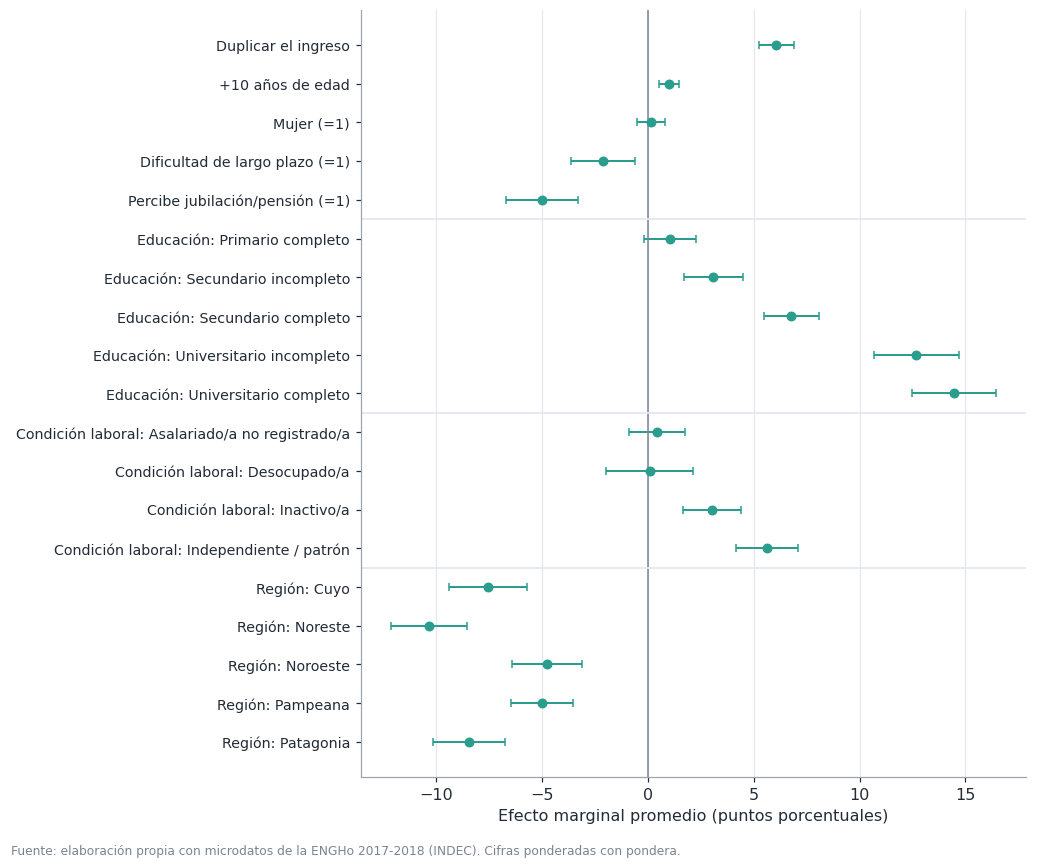

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/E4_efectos_marginales_A3.png
Epígrafe sugerido: Efectos marginales promedio sobre la probabilidad de tener prepaga (vía OS o voluntaria), con IC del 95%. Referencias: primario incompleto, asalariado registrado, región Metropolitana


In [33]:
import textwrap
from matplotlib.ticker import FuncFormatter

def forest(series, nombre, titulo, epigrafe, subt, figsize=(9.5, 8.2), xlabel="Efecto marginal promedio (puntos porcentuales)"):
    # series: {nombre: (DataFrame de efectos marginales, color)}
    primero = next(iter(series.values()))[0]
    filas = [i for i in primero.index if "derivada" not in i]
    n = len(filas)
    fig, ax = plt.subplots(figsize=figsize)
    k = len(series)
    desp = np.linspace(-0.17, 0.17, k) if k > 1 else [0.0]
    for (nom, (t, color)), dsp in zip(series.items(), desp):
        y = np.arange(n)[::-1] + dsp
        est = t.loc[filas, "ame_pp"].values
        err = 1.96 * t.loc[filas, "se_pp"].values
        ax.errorbar(est, y, xerr=err, fmt="o", color=color, ecolor=color, elinewidth=1.3, capsize=2.5, ms=5.5, label=nom)
    ax.axvline(0, color="#7A8492", lw=1)
    prev = None
    for i, f in enumerate(filas):
        grupo = f.split(":")[0] if ":" in f else "x"
        if prev is not None and grupo != prev and (":" in f or ":" in filas[i - 1]):
            ax.axhline(n - i - 0.5, color=GRILLA, lw=1.2)
        prev = grupo
    ax.set_yticks(np.arange(n)[::-1])
    ax.set_yticklabels(filas, fontsize=9.3)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    if k > 1:
        ax.legend(loc="lower right", fontsize=9.5)
    encabezado(fig, titulo, subt)
    fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
    guardar(fig, nombre, epigrafe)

# ---------- E4. Efectos marginales del modelo A3 ----------
forest({"A3: prepaga total": (MOD["A3"]["ame"], COL[ETQ_COB[2]])}, "E4_efectos_marginales_A3",
       "Efectos marginales sobre la probabilidad de tener prepaga",
       "Efectos marginales promedio sobre la probabilidad de tener prepaga (vía OS o voluntaria), con IC del 95%. Referencias: primario incompleto, asalariado registrado, región Metropolitana",
       f"Modelo A3 (N = {miles(MOD['A3']['n'])})")

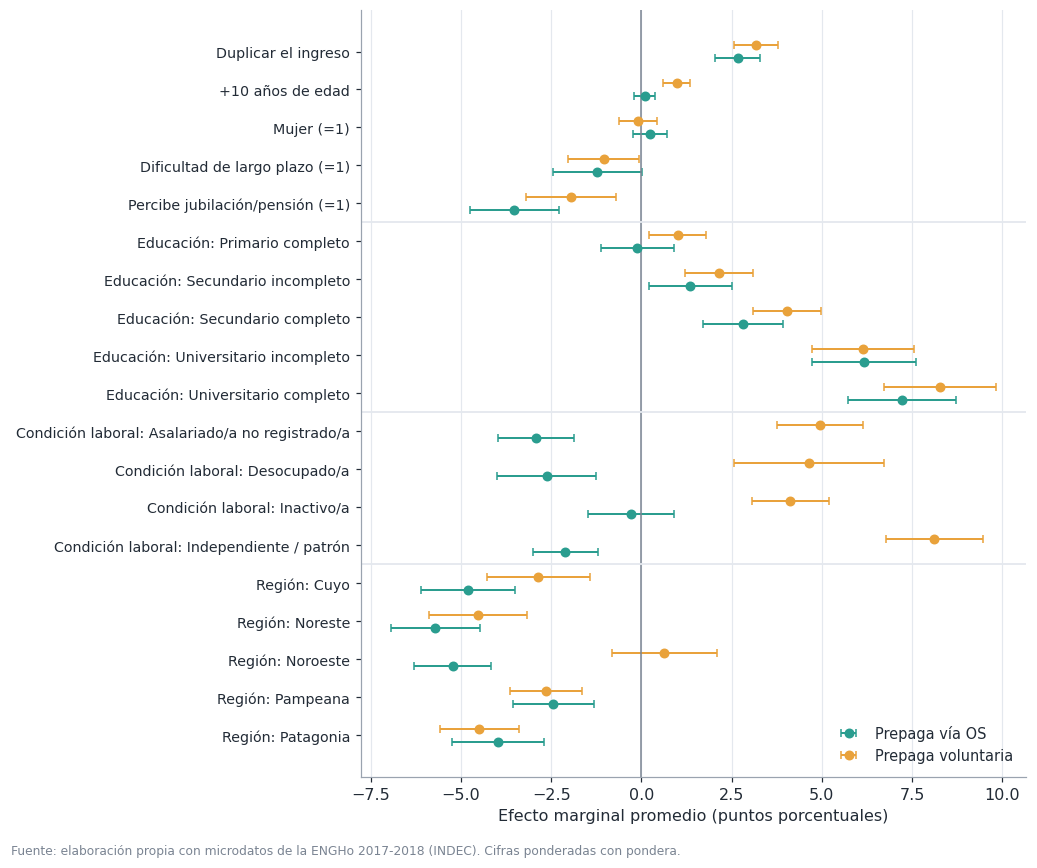

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/E5_efectos_marginales_por_canal.png
Epígrafe sugerido: Efectos marginales promedio del multinomial sobre la probabilidad de prepaga vía OS y de prepaga voluntaria, con IC del 95%


In [34]:
# ---------- E5. Efectos marginales por canal (multinomial) ----------
forest({ETQ_COB[2]: (MOD["B"]["ame"][ETQ_COB[2]], COL[ETQ_COB[2]]),
        ETQ_COB[3]: (MOD["B"]["ame"][ETQ_COB[3]], COL[ETQ_COB[3]])}, "E5_efectos_marginales_por_canal",
       "Efectos marginales sobre la probabilidad de cada tipo de prepaga",
       "Efectos marginales promedio del multinomial sobre la probabilidad de prepaga vía OS y de prepaga voluntaria, con IC del 95%",
       f"Modelo B (N = {miles(MOD['B']['n'])})")

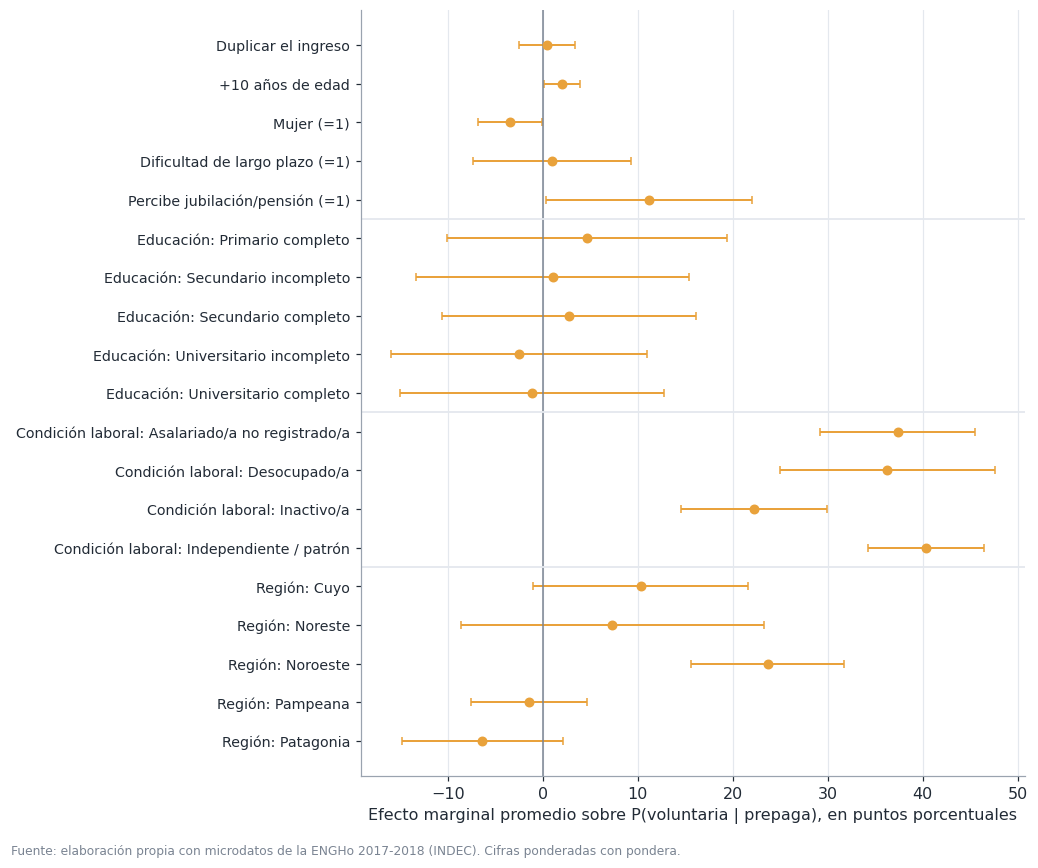

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/E6_efectos_marginales_C.png
Epígrafe sugerido: Efectos marginales promedio sobre la probabilidad de que la prepaga sea voluntaria (y no vía OS), entre adultos con prepaga, con IC del 95%


In [35]:
# ---------- E6. Efectos marginales del modelo C ----------
forest({"C: voluntaria vs vía OS": (MOD["C"]["ame"], COL[ETQ_COB[3]])}, "E6_efectos_marginales_C",
       "Qué distingue a la prepaga voluntaria de la prepaga vía OS",
       "Efectos marginales promedio sobre la probabilidad de que la prepaga sea voluntaria (y no vía OS), entre adultos con prepaga, con IC del 95%",
       f"Modelo C (N = {miles(MOD['C']['n'])})", figsize=(9.5, 8.2),
       xlabel="Efecto marginal promedio sobre P(voluntaria | prepaga), en puntos porcentuales")

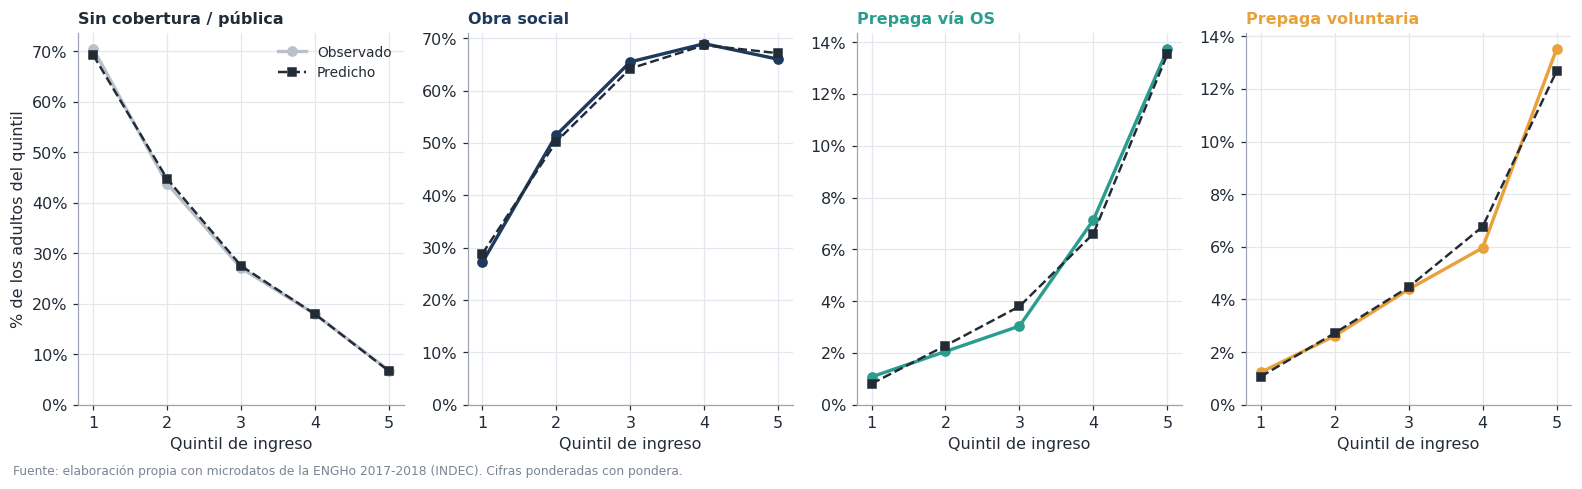

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/E7_observado_vs_predicho_por_quintil.png
Epígrafe sugerido: Porcentaje observado y predicho por el multinomial de cada cobertura, según quintil de ingreso per cápita del hogar


In [36]:
# ---------- E7. Composición observada y predicha por quintil ----------
Pm = _probs(mb["X"].values @ mb["B"])
wv = df["pondera"].values
fig, axes = plt.subplots(1, 4, figsize=(14.5, 4.6), sharex=True)
for j, (ax, cob) in enumerate(zip(axes, ETQ_COB)):
    obs, pred = [], []
    for q in range(1, 6):
        msk = (df["quintil"] == q).values
        obs.append(np.average((df["cobertura"] == cob).values[msk], weights=wv[msk]) * 100)
        pred.append(np.average(Pm[msk, j], weights=wv[msk]) * 100)
    ax.plot(range(1, 6), obs, marker="o", lw=2.2, color=COL[cob], label="Observado")
    ax.plot(range(1, 6), pred, marker="s", ms=5, lw=1.6, ls="--", color=TINTA, label="Predicho")
    ax.set_title(cob, loc="left", fontweight="bold", fontsize=10.5, color=COL[cob] if cob != ETQ_COB[0] else TINTA)
    ax.set_xticks(range(1, 6))
    ax.set_xlabel("Quintil de ingreso")
    fmt_pct_eje(ax)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("% de los adultos del quintil")
axes[0].legend(loc="upper right", fontsize=9)
encabezado(fig, "Composición observada y predicha por quintil de ingreso", f"Modelo B (N = {miles(mb['n'])})")
fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
guardar(fig, "E7_observado_vs_predicho_por_quintil", "Porcentaje observado y predicho por el multinomial de cada cobertura, según quintil de ingreso per cápita del hogar")

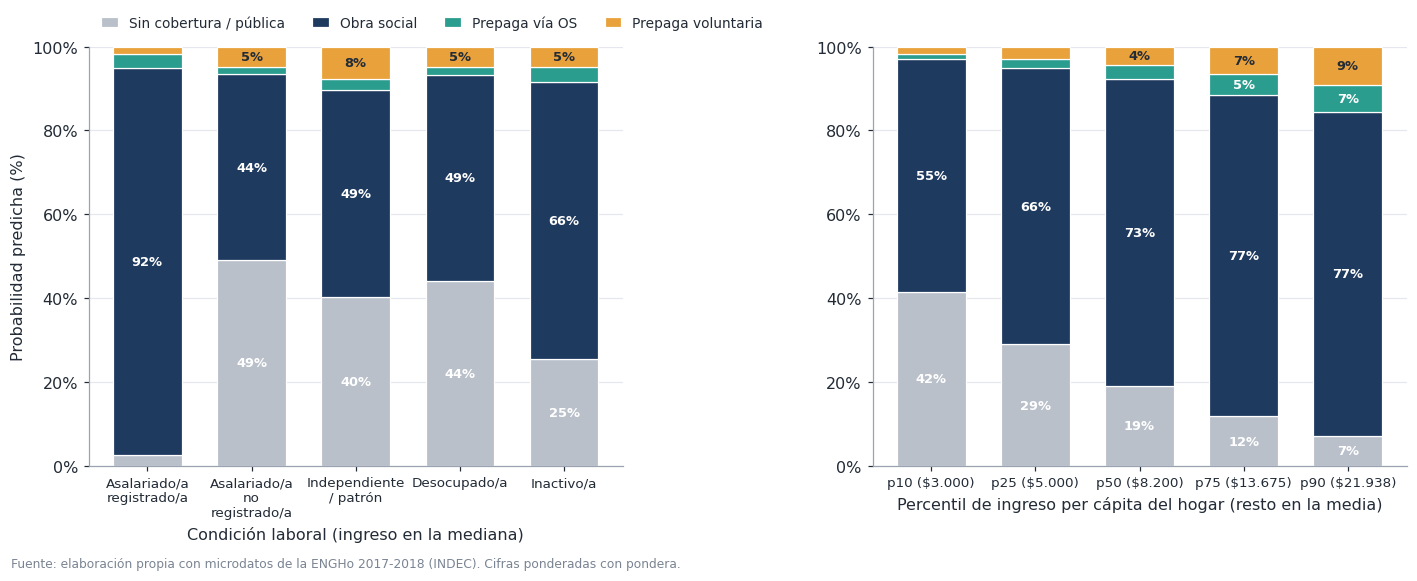

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/E8_probabilidades_por_perfil.png
Epígrafe sugerido: Probabilidad predicha de cada cobertura según condición laboral (ingreso en la mediana) y según percentil de ingreso (resto de las características en la media)


,Sin cobertura / pública,Obra social,Prepaga vía OS,Prepaga voluntaria
Asalariado/a registrado/a,2.6,92.2,3.4,1.7
Asalariado/a no registrado/a,49.0,44.4,1.8,4.8
Independiente / patrón,40.3,49.4,2.5,7.8
Desocupado/a,44.1,49.2,2.0,4.8
Inactivo/a,25.4,66.1,3.6,4.9


,Sin cobertura / pública,Obra social,Prepaga vía OS,Prepaga voluntaria
p10\n($3.000),41.5,55.4,1.3,1.8
p25\n($5.000),29.0,66.0,2.2,2.9
p50\n($8.200),19.1,73.1,3.3,4.5
p75\n($13.675),11.8,76.8,4.8,6.6
p90\n($21.938),7.2,77.1,6.6,9.1


In [37]:
# ---------- E8. Probabilidades predichas para perfiles tipo ----------
def fila_perfil(m, ing=None, cond=None):
    # Perfil: resto de las características en la media ponderada de la muestra
    X = m["X"]
    x = pd.Series(np.average(X.values, axis=0, weights=m["w"]), index=X.columns)
    if ing is not None:
        x["log_ingpch"] = np.log(ing)
    if cond is not None:
        for c in [c for c in X.columns if c.startswith("cond_lab_")]:
            x[c] = 0.0
        if cond != "asal_reg":
            x[f"cond_lab_{cond}"] = 1.0
    return x

def prob_perfil(m, x):
    return _probs((x.values @ m["B"])[None, :])[0]

ing_med = cuantil_np(df["ingpch"].values, df["pondera"].values, 0.5)
pcts = {p: cuantil_pond(df["ingpch"], df["pondera"], p / 100) for p in (10, 25, 50, 75, 90)}

perf_lab = pd.DataFrame({COND_LAB[c]: prob_perfil(mb, fila_perfil(mb, ing=ing_med, cond=c)) for c in COND_LAB}, index=ETQ_COB).T * 100
perf_ing = pd.DataFrame({f"p{p}\n(${miles(v)})": prob_perfil(mb, fila_perfil(mb, ing=v)) for p, v in pcts.items()}, index=ETQ_COB).T * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [5, 5]})
for ax, tab, xl in zip(axes, [perf_lab, perf_ing], ["Condición laboral (ingreso en la mediana)", "Percentil de ingreso per cápita del hogar (resto en la media)"]):
    base = np.zeros(len(tab))
    x = np.arange(len(tab))
    for g in ETQ_COB:
        ax.bar(x, tab[g].values, bottom=base, color=COL[g], width=0.66, edgecolor="white", linewidth=0.8, label=g)
        color_txt = TINTA if g == ETQ_COB[3] else "white"
        for xi, b, v in zip(x, base, tab[g].values):
            if v >= 4:
                ax.text(xi, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color=color_txt, fontweight="bold")
        base += tab[g].values
    ax.set_xticks(x)
    ax.set_xticklabels([textwrap.fill(str(i), 13) for i in tab.index], fontsize=8.8)
    ax.set_xlabel(xl)
    ax.set_ylim(0, 100)
    fmt_pct_eje(ax)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Probabilidad predicha (%)")
axes[0].legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.01), fontsize=9, handlelength=1.2)
encabezado(fig, "Probabilidades predichas para perfiles tipo", f"Modelo B (N = {miles(mb['n'])})")
fig.tight_layout(rect=[0, 0.03, 1, margen_sup(True)])
guardar(fig, "E8_probabilidades_por_perfil", "Probabilidad predicha de cada cobertura según condición laboral (ingreso en la mediana) y según percentil de ingreso (resto de las características en la media)")
display(perf_lab.round(1)); display(perf_ing.round(1))

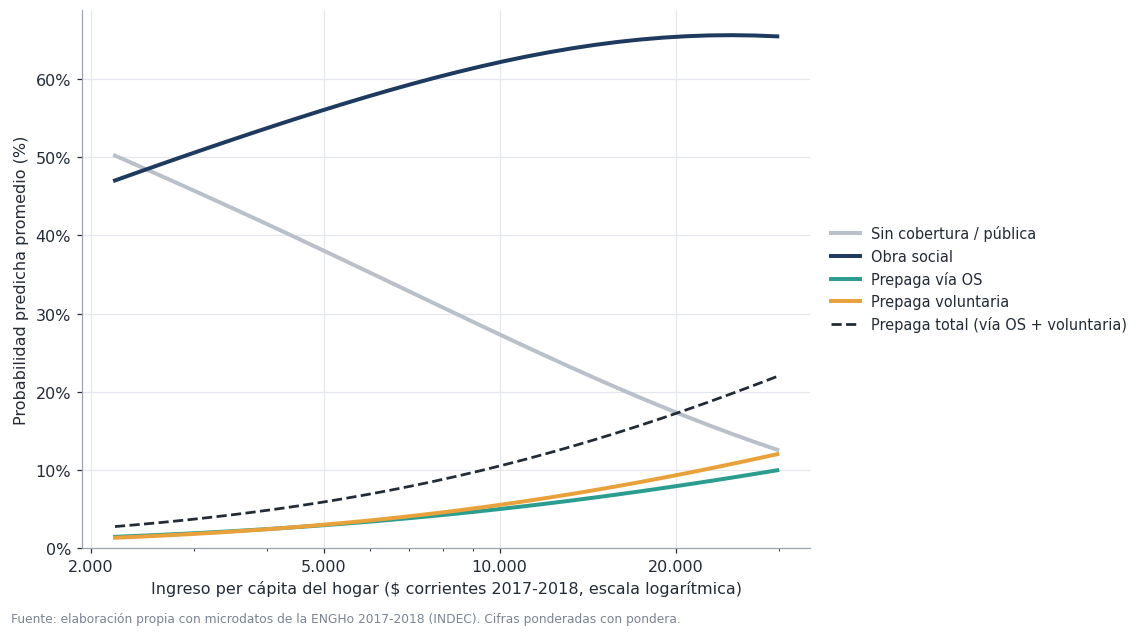

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/E9_curvas_probabilidad_ingreso.png
Epígrafe sugerido: Probabilidad predicha promedio de cada cobertura al variar el ingreso per cápita del hogar entre sus percentiles 5 y 95 (resto de las características observadas)


In [38]:
# ---------- E9. Curvas de probabilidad predicha según el ingreso ----------
grilla = np.exp(np.linspace(np.log(cuantil_pond(df["ingpch"], df["pondera"], 0.05)), np.log(cuantil_pond(df["ingpch"], df["pondera"], 0.95)), 30))
i_ing = list(mb["X"].columns).index("log_ingpch")
Xb = mb["X"].values.copy()
curvas = []
for g_ in grilla:
    Xg = Xb.copy()
    Xg[:, i_ing] = np.log(g_)
    curvas.append(np.average(_probs(Xg @ mb["B"]), axis=0, weights=mb["w"]) * 100)
curvas = np.array(curvas)

fig, ax = plt.subplots(figsize=(10.5, 6))
for j, cob in enumerate(ETQ_COB):
    ax.plot(grilla, curvas[:, j], lw=2.6, color=COL[cob], label=cob)
ax.plot(grilla, curvas[:, 2] + curvas[:, 3], lw=1.8, ls="--", color=TINTA, label="Prepaga total (vía OS + voluntaria)")
ax.set_xscale("log")
ticks = [t for t in (2000, 5000, 10000, 20000, 50000, 100000) if grilla[0] * 0.8 <= t <= grilla[-1] * 1.2]
ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: miles(v)))
ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax.set_xlabel("Ingreso per cápita del hogar ($ corrientes 2017-2018, escala logarítmica)")
ax.set_ylabel("Probabilidad predicha promedio (%)")
fmt_pct_eje(ax)
ax.set_ylim(bottom=0)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9.5)
encabezado(fig, "Probabilidad predicha de cada cobertura según el ingreso", f"Modelo B (N = {miles(mb['n'])})")
fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
guardar(fig, "E9_curvas_probabilidad_ingreso", "Probabilidad predicha promedio de cada cobertura al variar el ingreso per cápita del hogar entre sus percentiles 5 y 95 (resto de las características observadas)")

In [39]:
# ---------- E11. Tabla comparativa con Marchionni (1999) ----------
def lin_comb(m, col, ja, jb):
    # Diferencia de coeficientes entre las categorías ja y jb (0 = base) para la columna `col` del multinomial
    K, Jm1 = m["K"], m["J"] - 1
    k = list(m["X"].columns).index(col)
    v = np.zeros(K * Jm1)
    if ja > 0:
        v[(ja - 1) * K + k] += 1
    if jb > 0:
        v[(jb - 1) * K + k] -= 1
    est = float(v @ m["B"].ravel(order="F"))
    se = float(np.sqrt(v @ m["cov"] @ v))
    return est, se, 2 * stats.norm.sf(abs(est / se))

def pm(x, d=1):
    return f"{x:+.{d}f}".replace(".", ",")

amB = mb["ame"][ETQ_COB[0]]       # efectos sobre la probabilidad de no tener cobertura
def txt_ame(fila):
    r = amB.loc[fila]
    return f"{pm(r['ame_pp'])} p.p. en la probabilidad de no tener cobertura{estrellas(r['p'])} (EE {str(round(r['se_pp'], 2)).replace('.', ',')})"

def veredicto(fila, signo):
    r = amB.loc[fila]
    if r["p"] < 0.05 and np.sign(r["ame_pp"]) == signo:
        return "Sí"
    if np.sign(r["ame_pp"]) == signo:
        return "Parcial (mismo signo, no significativo al 5%)"
    return "No" if r["p"] < 0.05 else "No (sin efecto significativo)"

est_ing, se_ing, p_ing = lin_comb(mb, "log_ingpch", 3, 1)
est_ind, se_ind, p_ind = lin_comb(mb, "cond_lab_indep", 3, 1)
r_sex = amB.loc["Mujer (=1)"]

filas_m = [
    {"Hallazgo de Marchionni (1992, EPH, Área Metropolitana)": "El ingreso aumenta la probabilidad de tener cobertura (odds ratio 1,93, p<0,01)",
     "Esta estimación (2017-2018, ENGHo)": "Duplicar el ingreso: " + txt_ame("Duplicar el ingreso"),
     "¿Se sostiene?": veredicto("Duplicar el ingreso", -1),
     "Comparabilidad": "Su ingreso es por adulto equivalente; el nuestro, per cápita del hogar. Su variable es tener cobertura; la nuestra, no tenerla"},
    {"Hallazgo de Marchionni (1992, EPH, Área Metropolitana)": "Mayor nivel educativo, mayor probabilidad de cobertura (universitario completo: odds ratio 8,78 frente a primario incompleto)",
     "Esta estimación (2017-2018, ENGHo)": "Universitario completo: " + txt_ame("Educación: Universitario completo"),
     "¿Se sostiene?": veredicto("Educación: Universitario completo", -1),
     "Comparabilidad": "Su muestra excluye cónyuges, menores y jubilados; la nuestra incluye a todos los adultos"},
    {"Hallazgo de Marchionni (1992, EPH, Área Metropolitana)": "Los cuentapropistas tienen la menor probabilidad de cobertura (asalariados: odds ratio 10,75)",
     "Esta estimación (2017-2018, ENGHo)": "Independiente / patrón frente a asalariado registrado: " + txt_ame("Condición laboral: Independiente / patrón"),
     "¿Se sostiene?": veredicto("Condición laboral: Independiente / patrón", 1),
     "Comparabilidad": "Su referencia es el cuentapropista; la nuestra, el asalariado registrado. Se compara el sentido del contraste"},
    {"Hallazgo de Marchionni (1992, EPH, Área Metropolitana)": "La edad aumenta la probabilidad de tener cobertura (odds ratio 1,022 por año), sin jubilados en la muestra",
     "Esta estimación (2017-2018, ENGHo)": "+10 años de edad: " + txt_ame("+10 años de edad"),
     "¿Se sostiene?": veredicto("+10 años de edad", -1),
     "Comparabilidad": "Nuestra muestra incluye jubilados; se controla por percibir jubilación o pensión"},
    {"Hallazgo de Marchionni (1992, EPH, Área Metropolitana)": "El sexo no influye en la probabilidad de cobertura una vez controlado el rol en el hogar (p = 0,219)",
     "Esta estimación (2017-2018, ENGHo)": "Mujer: " + txt_ame("Mujer (=1)"),
     "¿Se sostiene?": "Sí" if r_sex["p"] >= 0.05 else "No",
     "Comparabilidad": "Ella controla por parentesco con el jefe del hogar; nosotros no"},
    {"Hallazgo de Marchionni (1992, EPH, Área Metropolitana)": "Entre los cubiertos, más ingreso implica más chances de seguros voluntarios",
     "Esta estimación (2017-2018, ENGHo)": f"Prepaga voluntaria frente a obra social: razón de riesgo relativo del ingreso = {np.exp(est_ing):.2f}".replace(".", ",") + f" (p {fmt_p(p_ing)})",
     "¿Se sostiene?": "Sí" if (est_ing > 0 and p_ing < 0.05) else ("Parcial (mismo signo, no significativo al 5%)" if est_ing > 0 else "No"),
     "Comparabilidad": "Sus categorías son obligatorio o voluntario; la contraparte más cercana en la ENGHo es obra social frente a prepaga voluntaria"},
    {"Hallazgo de Marchionni (1992, EPH, Área Metropolitana)": "Entre los cubiertos, los cuentapropistas son los más propensos a contratar seguros voluntarios",
     "Esta estimación (2017-2018, ENGHo)": f"Prepaga voluntaria frente a obra social: razón de riesgo relativo de ser independiente = {np.exp(est_ind):.2f}".replace(".", ",") + f" (p {fmt_p(p_ind)})",
     "¿Se sostiene?": "Sí" if (est_ind > 0 and p_ind < 0.05) else ("Parcial (mismo signo, no significativo al 5%)" if est_ind > 0 else "No"),
     "Comparabilidad": "Referencia: asalariado registrado en nuestro modelo"},
]
T6_marchionni = pd.DataFrame(filas_m)
pd.set_option("display.max_colwidth", 120)
display(T6_marchionni)
print("\nComparación cualitativa: las definiciones de ingreso, categorías y muestra no coinciden con las de Marchionni (1999).")

,"Hallazgo de Marchionni (1992, EPH, Área Metropolitana)","Esta estimación (2017-2018, ENGHo)",¿Se sostiene?,Comparabilidad
0,"El ingreso aumenta la probabilidad de tener cobertura (odds ratio 1,93, p<0,01)","Duplicar el ingreso: -8,9 p.p. en la probabilidad de no tener cobertura*** (EE 0,27)",Sí,"Su ingreso es por adulto equivalente; el nuestro, per cápita del hogar. Su variable es tener cobertura; la nuestra, ..."
1,"Mayor nivel educativo, mayor probabilidad de cobertura (universitario completo: odds ratio 8,78 frente a primario in...","Universitario completo: -21,0 p.p. en la probabilidad de no tener cobertura*** (EE 1,44)",Sí,"Su muestra excluye cónyuges, menores y jubilados; la nuestra incluye a todos los adultos"
2,"Los cuentapropistas tienen la menor probabilidad de cobertura (asalariados: odds ratio 10,75)","Independiente / patrón frente a asalariado registrado: +38,1 p.p. en la probabilidad de no tener cobertura*** (EE 0,94)",Sí,"Su referencia es el cuentapropista; la nuestra, el asalariado registrado. Se compara el sentido del contraste"
3,"La edad aumenta la probabilidad de tener cobertura (odds ratio 1,022 por año), sin jubilados en la muestra","+10 años de edad: -2,9 p.p. en la probabilidad de no tener cobertura*** (EE 0,21)",Sí,Nuestra muestra incluye jubilados; se controla por percibir jubilación o pensión
4,"El sexo no influye en la probabilidad de cobertura una vez controlado el rol en el hogar (p = 0,219)","Mujer: -2,9 p.p. en la probabilidad de no tener cobertura*** (EE 0,47)",No,Ella controla por parentesco con el jefe del hogar; nosotros no
5,"Entre los cubiertos, más ingreso implica más chances de seguros voluntarios","Prepaga voluntaria frente a obra social: razón de riesgo relativo del ingreso = 1,94 (p <0,001)",Sí,Sus categorías son obligatorio o voluntario; la contraparte más cercana en la ENGHo es obra social frente a prepaga ...
6,"Entre los cubiertos, los cuentapropistas son los más propensos a contratar seguros voluntarios","Prepaga voluntaria frente a obra social: razón de riesgo relativo de ser independiente = 8,50 (p <0,001)",Sí,Referencia: asalariado registrado en nuestro modelo



Comparación cualitativa: las definiciones de ingreso, categorías y muestra no coinciden con las de Marchionni (1999).


In [40]:
# ---------- E12. Misma especificación A3 solo en la región Metropolitana ----------
d_m = df[df["region"] == "Metropolitana"].copy()
CATS_NOREG = CATS_A2 + [("cond_lab", "asal_reg")]
MOD["A3_metro"] = ajustar_logit(d_m, "prepaga_total", CONT_A3, CATS_NOREG, "log_ingpch", "A3 Metropolitana")
mm_ = MOD["A3_metro"]
print(f"A3 Metropolitana: N = {mm_['n']:,} | pseudo-R² = {mm_['r2']:.3f} | AUC = {mm_['auc']:.3f} | tasa media = {mm_['tasa']*100:.1f}% | elasticidad = {mm_['elast']:.2f}")

ame_nac = MOD["A3"]["ame"][~MOD["A3"]["ame"].index.str.contains("derivada")]
ame_met = mm_["ame"][~mm_["ame"].index.str.contains("derivada")]
T7_metro = agregar_ajuste(
    tabla_ancha({"A3 nacional": ame_nac, "A3 región Metropolitana": ame_met}, "ame_pp", "se_pp", 2),
    [MOD["A3"], mm_], [MOD["A3"]["tasa"], mm_["tasa"]], [MOD["A3"]["elast"], mm_["elast"]])
display(T7_metro)

A3 Metropolitana: 200/200 réplicas válidas
A3 Metropolitana: N = 8,231 | pseudo-R² = 0.239 | AUC = 0.837 | tasa media = 16.2% | elasticidad = 0.72


,Variable,A3 nacional,A3 región Metropolitana
0,Duplicar el ingreso,6.06***,9.35***
1,,(0.42),(0.82)
2,+10 años de edad,1.00***,1.54***
3,,(0.24),(0.50)
4,Mujer (=1),0.16,0.20
5,,(0.34),(0.71)
6,Dificultad de largo plazo (=1),-2.13***,-3.30**
7,,(0.76),(1.64)
8,Percibe jubilación/pensión (=1),-5.03***,-4.10**
9,,(0.86),(1.94)


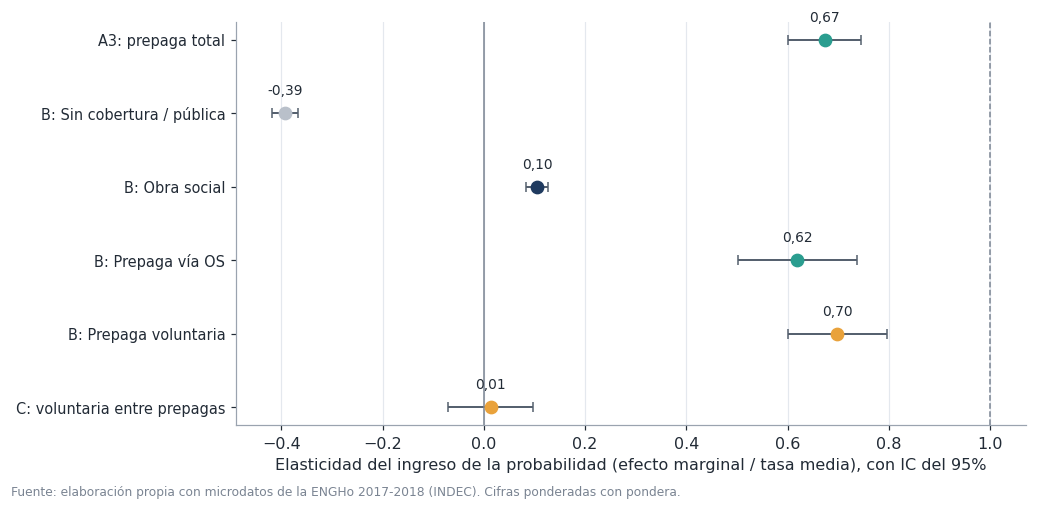

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/E13_elasticidad_ingreso.png
Epígrafe sugerido: Elasticidad del ingreso de la probabilidad de cada categoría de cobertura, con IC del 95%. La línea punteada marca la elasticidad unitaria


,Categoría,Elasticidad,Error estándar
0,A3: prepaga total,0.673,0.037
1,B: Sin cobertura / pública,-0.393,0.013
2,B: Obra social,0.105,0.011
3,B: Prepaga vía OS,0.619,0.060
4,B: Prepaga voluntaria,0.698,0.050
5,C: voluntaria entre prepagas,0.013,0.043


In [41]:
# ---------- E13. Elasticidad-ingreso por categoría ----------
def elast_se(m, cat=None):
    # Elasticidad y su error por réplicas
    return (m["elast"], m["elast_se"]) if cat is None else (m["elast"][cat], m["elast_se"][cat])

pts = [("A3: prepaga total", COL[ETQ_COB[2]], *elast_se(MOD["A3"]))]
for cat in ETQ_COB:
    pts.append((f"B: {cat}", COL[cat], *elast_se(mb, cat)))
pts.append(("C: voluntaria entre prepagas", COL[ETQ_COB[3]], *elast_se(MOD["C"])))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
y = np.arange(len(pts))[::-1]
for yi, (nom, color, e, s) in zip(y, pts):
    ax.errorbar([e], [yi], xerr=[1.96 * s], fmt="o", color=color, ecolor="#55606E", elinewidth=1.3, capsize=3, ms=8)
    ax.text(e, yi + 0.25, f"{e:.2f}".replace(".", ","), ha="center", fontsize=9)
ax.axvline(0, color="#7A8492", lw=1)
ax.axvline(1, color="#7A8492", lw=1, ls="--")
ax.set_yticks(y)
ax.set_yticklabels([p[0] for p in pts], fontsize=9.5)
ax.set_xlabel("Elasticidad del ingreso de la probabilidad (efecto marginal / tasa media), con IC del 95%")
ax.grid(axis="y", visible=False)
encabezado(fig, "Elasticidad-ingreso de la probabilidad, por categoría", "Modelos A3, B y C")
fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
guardar(fig, "E13_elasticidad_ingreso", "Elasticidad del ingreso de la probabilidad de cada categoría de cobertura, con IC del 95%. La línea punteada marca la elasticidad unitaria")
T_elast = pd.DataFrame([{"Categoría": p[0], "Elasticidad": round(p[2], 3), "Error estándar": round(p[3], 3)} for p in pts])
display(T_elast)

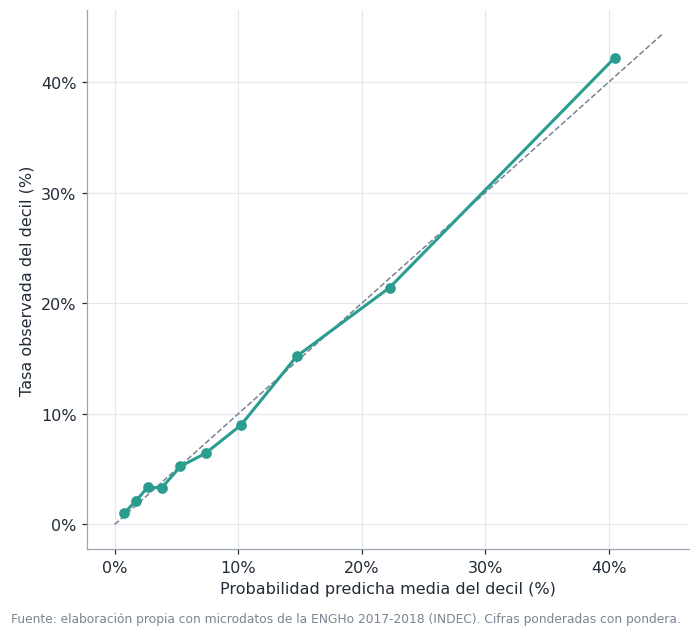

Guardado: /content/drive/MyDrive/TP/Resultados/graficos/E14_calibracion_A3.png
Epígrafe sugerido: Tasa observada de prepaga frente a la probabilidad predicha por el modelo A3, por deciles de probabilidad predicha (ponderado)


,Predicho,Observado
1,0.78,1.05
2,1.70,2.10
3,2.67,3.37
4,3.82,3.32
5,5.32,5.25
6,7.37,6.45
7,10.22,8.98
8,14.73,15.20
9,22.26,21.42
10,40.48,42.19


In [42]:
# ---------- E14. Calibración del modelo A3 por deciles de probabilidad predicha ----------
m3 = MOD["A3"]
p_hat = _probs(m3["X"].values @ m3["B"])[:, 1]
o = np.argsort(p_hat)
cw = np.cumsum(m3["w"][o]) / m3["w"].sum()
dec = np.minimum((cw * 10).astype(int), 9)
filas_cal = []
for k in range(10):
    idx = o[dec == k]
    filas_cal.append((np.average(p_hat[idx], weights=m3["w"][idx]) * 100, np.average(m3["yv"][idx], weights=m3["w"][idx]) * 100))
cal = pd.DataFrame(filas_cal, columns=["Predicho", "Observado"], index=range(1, 11))

fig, ax = plt.subplots(figsize=(6.4, 6))
ax.plot([0, cal.values.max() * 1.05], [0, cal.values.max() * 1.05], color="#7A8492", lw=1, ls="--")
ax.plot(cal["Predicho"], cal["Observado"], marker="o", lw=2, color=COL[ETQ_COB[2]])
ax.set_xlabel("Probabilidad predicha media del decil (%)")
ax.set_ylabel("Tasa observada del decil (%)")
fmt_pct_eje(ax, "x"); fmt_pct_eje(ax)
encabezado(fig, "Calibración del modelo A3", f"Modelo A3 (N = {miles(m3['n'])})")
fig.tight_layout(rect=[0, 0.03, 1, margen_sup()])
guardar(fig, "E14_calibracion_A3", "Tasa observada de prepaga frente a la probabilidad predicha por el modelo A3, por deciles de probabilidad predicha (ponderado)")
display(cal.round(2))

## Módulo 9. Pruebas de robustez (E10)

Se repiten el modelo A3 (prepaga total) y el modelo C (voluntaria frente a vía OS) con la especificación base y tres alternativas. Una cuarta alternativa (la última de la lista) se aplica solo al modelo C. Todos los errores salen de las réplicas de INDEC:

1. **Base:** especificación de cada modelo.
2. **Ingreso individual:** se reemplaza `log_ingpch` por `log_ingtotp`, lo que restringe la muestra a los perceptores.
3. **Sin hogares con ingreso imputado:** se excluyen los adultos de hogares con `m_ingtoth == 1`.
4. **Sin PAMI:** se excluyen los adultos que declaran PAMI. Verifica que los resultados no dependan de la parte de la obra social que es PAMI.
5. **Sin prepaga voluntaria complementaria (solo modelo C):** se excluyen los adultos con prepaga voluntaria que además declaran obra social o PAMI. Verifica que los resultados no dependan de la parte de la voluntaria que complementa a otra cobertura.

Para cada especificación se reportan el odds ratio del ingreso, el efecto de duplicarlo (en p.p.), la elasticidad, el efecto de ser independiente o patrón frente a asalariado registrado (en p.p.) y el N.

In [43]:
def correr_variante(d, y, ing_col):
    d = d.dropna(subset=[ing_col])
    return ajustar_logit(d, y, [ing_col if c == "log_ingpch" else c for c in CONT_A3], CATS_A3, ing_col)

def fila_robustez(nombre, m, ing_col):
    lab = etiqueta(ing_col)
    r = m["coef"].loc[lab]
    a = m["ame"].loc["Duplicar el ingreso"]
    i = m["ame"].loc["Condición laboral: Independiente / patrón"]
    return {"Variante": nombre, "Odds ratio del ingreso": f"{r['or']:.3f}{estrellas(r['p'])}", "EE (OR)": f"({r['or_se']:.3f})",
            "Duplicar ingreso (p.p.)": f"{a['ame_pp']:.2f}{estrellas(a['p'])}", "EE (p.p.)": f"({a['se_pp']:.2f})",
            "Elasticidad": f"{m['elast']:.2f}",
            "Independiente vs asal. registrado (p.p.)": f"{i['ame_pp']:.2f}{estrellas(i['p'])}", "EE ": f"({i['se_pp']:.2f})",
            "N": miles(m["n"])}

variantes = {
    "Base": (lambda d: d, "log_ingpch"),
    "Ingreso individual (perceptores)": (lambda d: d, "log_ingtotp"),
    "Sin hogares con ingreso imputado": (lambda d: d[d["hogar_imputado"] == 0], "log_ingpch"),
    "Sin adultos que declaran PAMI": (lambda d: d[d["pami"] == 0], "log_ingpch"),
    "Sin prepaga voluntaria complementaria": (lambda d: d[~((d["cobertura"] == ETQ_COB[3]) & (d["complemento"] == 1))], "log_ingpch"),
}

bloques = {}
for titulo, (base_df, y) in {"A3: prepaga total": (df, "prepaga_total"), "C: voluntaria vs vía OS": (d_c, "y_vol")}.items():
    filas_r = []
    for nom, (filtro, ing_col) in variantes.items():
        if titulo.startswith("A3") and nom.startswith("Sin prepaga voluntaria"):
            continue
        m = correr_variante(filtro(base_df), y, ing_col)
        filas_r.append(fila_robustez(nom, m, ing_col))
    bloques[titulo] = pd.DataFrame(filas_r)
    print(f"\n{titulo}")
    display(bloques[titulo])

T5_robustez = pd.concat([b.assign(Modelo=t) for t, b in bloques.items()], ignore_index=True)
T5_robustez = T5_robustez[["Modelo"] + [c for c in T5_robustez.columns if c != "Modelo"]]

prepaga_total: 200/200 réplicas válidas
prepaga_total: 200/200 réplicas válidas
prepaga_total: 200/200 réplicas válidas
prepaga_total: 200/200 réplicas válidas

A3: prepaga total


,Variante,Odds ratio del ingreso,EE (OR),Duplicar ingreso (p.p.),EE (p.p.),Elasticidad,Independiente vs asal. registrado (p.p.),EE,N
0,Base,2.442***,(0.131),6.06***,(0.42),0.67,5.62***,(0.75),48.363
1,Ingreso individual (perceptores),1.688***,(0.077),3.45***,(0.32),0.40,6.74***,(0.78),41.161
2,Sin hogares con ingreso imputado,2.451***,(0.141),6.25***,(0.46),0.68,5.68***,(0.90),35.183
3,Sin adultos que declaran PAMI,2.308***,(0.130),5.96***,(0.45),0.63,5.90***,(0.81),41.478


y_vol: 200/200 réplicas válidas
y_vol: 200/200 réplicas válidas
y_vol: 200/200 réplicas válidas
y_vol: 200/200 réplicas válidas
y_vol: 200/200 réplicas válidas

C: voluntaria vs vía OS


,Variante,Odds ratio del ingreso,EE (OR),Duplicar ingreso (p.p.),EE (p.p.),Elasticidad,Independiente vs asal. registrado (p.p.),EE,N
0,Base,1.034,(0.114),0.46,(1.52),0.01,40.39***,(3.11),3.955
1,Ingreso individual (perceptores),1.026,(0.083),0.34,(1.09),0.01,41.10***,(3.18),3.429
2,Sin hogares con ingreso imputado,1.008,(0.128),0.10,(1.61),0.00,38.70***,(4.21),2.882
3,Sin adultos que declaran PAMI,1.026,(0.118),0.37,(1.62),0.01,41.26***,(3.18),3.578
4,Sin prepaga voluntaria complementaria,1.006,(0.121),0.09,(1.63),0.00,47.16***,(3.17),3.343


## Módulo 10. Exportación de tablas a Excel

Todas las tablas se guardan en un único libro, `tablas_TP_prepagas_v4.xlsx`, dentro de `Resultados/`. Cada tabla ocupa una hoja, con encabezado destacado, columnas ajustadas y primera fila fija. La hoja `Notas` documenta las convenciones.

In [44]:
from openpyxl.styles import Font, PatternFill, Alignment

notas = pd.DataFrame({"Notas": [
    "Fuente: ENGHo 2017-2018 (INDEC). Universo: adultos de 18 años o más. Cifras ponderadas con pondera, sin normalizar.",
    "Cobertura (mutuamente excluyente): prepaga voluntaria > prepaga vía OS > obra social (incluye PAMI) > sin cobertura / pública.",
    "Modelos: logit de máxima verosimilitud ponderada con pondera (sin normalizar). Errores estándar por las 200 réplicas bootstrap de INDEC (Nota técnica n.º 4). Significatividad (prueba z): *** p<0,01; ** p<0,05; * p<0,10. Entre paréntesis: error estándar.",
    "Calidad de las cifras descriptivas (estándar de INDEC, Cuadro 4): ‡ = no confiable (menos de 100 casos, proporción menor al 3% o CV mayor a 33,3%); † = poco confiable (CV entre 16,6% y 33,3%). Los CV están en las hojas con sufijo _CV.",
    "Referencias: educación = hasta primario incompleto; condición laboral = asalariado/a registrado/a; región = Metropolitana.",
    "Efectos marginales: promedio ponderado, en puntos porcentuales. Variables binarias y categóricas: cambio de 0 a 1 (o desde la categoría de referencia). Continuas: derivada.",
    "Elasticidad del ingreso = derivada del efecto marginal / tasa media ponderada de la categoría.",
    "Bloques: A = logit de prepaga total (A1 a A3); B = multinomial de cuatro coberturas (referencia: sin cobertura / pública; razones de riesgo relativo); C = logit de prepaga voluntaria frente a prepaga vía OS, solo entre adultos con prepaga.",
    "Tablas 2 a 4: la constante no se reporta. Pseudo-R² de McFadden con verosimilitud ponderada. AUC ponderado (multinomial: promedio uno contra el resto).",
    "Tabla V: diferencia entre prepaga voluntaria y vía OS (p.p. en proporciones) y p-valor de la prueba z con el error por réplicas.",
    "PAMI está dentro de la categoría obra social. No es regresor (predicción perfecta en el multinomial); se controla por edad y jubilación y se verifica en la robustez.",
    "Tabla 6 (Marchionni): comparación cualitativa. Las definiciones de ingreso, categorías y muestra no coinciden con las de Marchionni (1999).",
]})

hojas = {
    "Notas": notas,
    "Embudo": tabla_embudo,
    "T1_Descriptiva": tabla1,
    "T1_CV": tabla1_cv,
    "T1c_Compacta_M10": tabla1c,
    "T1c_CV": tabla1c_cv,
    "TV_ViaOS_vs_Vol_V7": tablaV,
    "TV_CV": tablaV_cv,
    "T2a_Logit_OR_E1": T2_or,
    "T2b_Logit_Coef": T2_coef,
    "T2c_Logit_AME_E1": T2_ame,
    "T3a_Multinomial_RRR_E2": T3_rrr,
    "T3b_Multinomial_AME_E2": T3_ame,
    "T4a_VolVsVia_OR_E3": T4_or,
    "T4b_VolVsVia_AME_E3": T4_ame,
    "T5_Robustez_E10": T5_robustez,
    "T6_Marchionni_E11": T6_marchionni,
    "T7_Metropolitana_E12": T7_metro,
    "T8_Elasticidades_E13": T_elast,
    "T9_Ajuste_modelos": T_ajuste,
}

ruta_xlsx = os.path.join(RUTA_SALIDA, "tablas_TP_prepagas_v4.xlsx")
with pd.ExcelWriter(ruta_xlsx, engine="openpyxl") as xw:
    for nombre, tabla in hojas.items():
        tabla.to_excel(xw, sheet_name=nombre[:31], index=False)
    for ws in xw.book.worksheets:
        for celda in ws[1]:
            celda.font = Font(bold=True, color="FFFFFF")
            celda.fill = PatternFill("solid", fgColor="1F3A5F")
            celda.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        for col in ws.columns:
            ancho = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            ws.column_dimensions[col[0].column_letter].width = min(max(12, ancho + 2), 60)
        ws.freeze_panes = "B2" if ws.title != "Notas" else "A2"

print("Tablas guardadas en:", ruta_xlsx)
print("Gráficos guardados en:", RUTA_GRAFICOS)

Tablas guardadas en: /content/drive/MyDrive/TP/Resultados/tablas_TP_prepagas_v4.xlsx
Gráficos guardados en: /content/drive/MyDrive/TP/Resultados/graficos


## Cierre

Con la ejecución completa quedan en `Resultados/`:

- `graficos/`: M1 a M9, V1 a V8 y E4 a E14 en PNG de 300 dpi (M7, el mapa por provincia, no se genera).
- `tablas_TP_prepagas_v4.xlsx`: embudo, Tabla 1 (completa y compacta), Tabla V, Tablas 2 a 4 (modelos), Tabla 5 (robustez), comparación con Marchionni, región Metropolitana, elasticidades y ajuste.
- `base_analisis_adultos.csv`: base final de análisis.

**Notas para la redacción**

- Los resultados son asociaciones condicionales, no efectos causales. Las cifras están ponderadas con `pondera` y describen a la población adulta. Los errores estándar incorporan el diseño muestral a través de las 200 réplicas bootstrap de INDEC.
- Las cifras descriptivas con marca `‡` o `†` no alcanzan el estándar de calidad de INDEC y deben leerse con cautela o evitarse.
- El universo son los adultos de 18 años o más, porque la cobertura de salud se declara a nivel individual. Los menores se excluyen porque su cobertura depende de la de sus adultos.
- El ingreso se mide como ingreso per cápita del hogar, que existe para todos los adultos. La variante con ingreso individual (solo perceptores) está en la Tabla 5.
- La cobertura es una declaración individual: la ENGHo no identifica quién es el titular del contrato. La categoría "Prepaga voluntaria" incluye a quienes además declaran obra social o PAMI, por lo que parte de la voluntaria es complemento y no sustitución (Tabla V y Tabla 5).
- PAMI está dentro de la categoría obra social. Se verifica en la Tabla 5 que los resultados no dependan de ella.
- Las prepagas vía obra social y voluntaria tienen alrededor de 1.800 a 2.100 casos cada una, de modo que las aperturas finas (por región o por condición laboral) deben leerse con cautela; en particular, las regiones Noreste y Cuyo.
- Las probabilidades predichas (E7 a E9) y la calibración (E14) son estimaciones puntuales sin intervalo.
- La comparación con Marchionni (1999) es cualitativa: las definiciones de ingreso, las categorías de cobertura y la muestra no coinciden.